# Tutorial — Bayesian PCE regression with an unknown noise level

This notebook builds a Bayesian polynomial chaos expansion (PCE) from the
ground up and uses it to show **why an implicit, Langevin-based posterior is
worth having**. We go step by step:

1. **Data and model.** Nine noisy observations, a degree-5 Legendre PCE.
2. **Prior.** What the prior says about coefficients, noise, and functions
   (the prior *pushforward* through the PCE).
3. **Warm-up: known noise.** With $\sigma$ fixed the posterior is exactly
   Gaussian, and everything about it scales with $\sigma$.
4. **Unknown noise: the exact posterior.** Inferring $\sigma$ jointly turns
   the posterior into a curved *funnel*. Thanks to conjugacy we can compute
   it exactly, so it serves as ground truth for everything that follows.
5. **Gaussian variational families.** Mean-field and full-covariance
   Gaussians, trained with `pypolymix`, and the best any Gaussian could do.
6. **The Langevin generator.** A score network drives 60 Langevin steps that
   carry a particle cloud from a simple initial distribution to the
   posterior. We look inside: particles over pseudo-time, the learned score
   field, and the function draws along the way.
7. **Comparison.** KL divergence, posterior shape, the noise marginal, and
   the posterior predictive, against the exact answer.

**Why this problem.** A PCE is linear in its coefficients, so with a known
noise level and a Gaussian prior the posterior is Gaussian and a
full-covariance Gaussian is exact. The one realistic change made here, not
knowing the noise level with a small budget of data, is enough to make the
posterior non-Gaussian in a way no Gaussian family can capture.

Feasibility scan behind the choice of problem: `experiments/loglink_scan/`.
Expensive cells are cached under `docs/examples/.cache/toy_pce_unknown_noise/`.
This notebook is generated by `experiments/loglink_scan/nb_builder/build.py`.

In [1]:
import time

_notebook_start = time.time()

In [2]:
import math
import pathlib
import sys

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F
from torch.optim.lr_scheduler import OneCycleLR

from pypolymix.parameter_groups import GaussianGroup, IIDGaussianGroup, LangevinGroup
from pypolymix.parameter_groups.kl_estimators import KNNEntropyKL, _knn_entropy
from pypolymix.priors import GaussianPrior, IIDGaussianPrior
from pypolymix.surrogate_models import NeuralNetwork, PolynomialChaosExpansion

torch.set_default_dtype(torch.float64)

for _candidate in [pathlib.Path("docs/examples"), pathlib.Path(".")]:
    if (_candidate / "_cache_utils.py").exists():
        sys.path.insert(0, str(_candidate))
        NOTEBOOK_DIR = _candidate
        break
else:
    raise RuntimeError("Could not locate _cache_utils.py -- run from the repo root or docs/examples/.")

from _cache_utils import CacheDir

FORCE_RECOMPUTE = False
cache = CacheDir(NOTEBOOK_DIR / ".cache" / "toy_pce_unknown_noise", force=FORCE_RECOMPUTE)
PAPER_DAT_DIR = pathlib.Path.home() / "projects/salt/doc/paper/stochastic_surrogates/dat"

FAMILIES = ["iid", "full", "langevin"]
FAMILY_LABELS = {"iid": "Mean-field Gaussian", "full": "Full-covariance Gaussian", "langevin": "Langevin",
                 "exact": "Exact posterior"}
FAMILY_COLORS = {"iid": "tab:blue", "full": "tab:green", "langevin": "tab:red", "exact": "0.3"}
LOG2PI = math.log(2 * math.pi)

## 1. Data

The "simulator" is $f(x) = \sin(1.5\pi x) + 0.3x$ on $[-1, 1]$. We observe
it at $n = 9$ roughly equispaced inputs, with Gaussian noise of standard
deviation $\sigma_\mathrm{true} = 0.1$. Nine runs is a realistic budget for
an expensive simulator or a physical experiment.

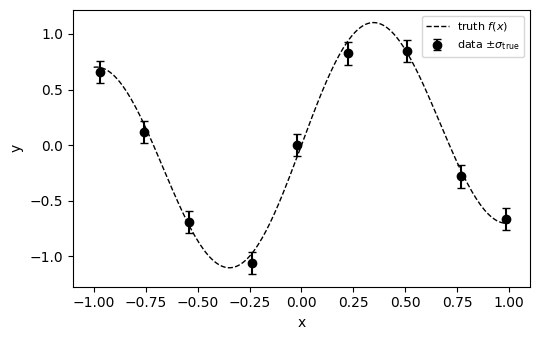

In [3]:
N_TRAIN, DEGREE, SIGMA_TRUE, DATA_SEED = 9, 5, 0.1, 0


def truth(x):
    return torch.sin(1.5 * math.pi * x) + 0.3 * x


_g = torch.Generator().manual_seed(DATA_SEED)
x_train = (torch.linspace(-1, 1, N_TRAIN) + 0.02 * torch.randn(N_TRAIN, generator=_g)).clamp(-1, 1)
y_train = truth(x_train) + SIGMA_TRUE * torch.randn(N_TRAIN, generator=_g)
x_train = x_train.unsqueeze(-1)

X_BAND = torch.linspace(-1, 1, 201).unsqueeze(-1)  # plotting grid used throughout
XB = X_BAND[:, 0]

_, ax = plt.subplots(figsize=(5.5, 3.5))
ax.plot(XB, truth(XB), "k--", lw=1, label="truth $f(x)$")
ax.errorbar(x_train[:, 0], y_train, yerr=SIGMA_TRUE, fmt="o", color="k", capsize=3,
            label=r"data $\pm\sigma_\mathrm{true}$")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.legend(fontsize=8)
plt.tight_layout()

## 2. The surrogate: a degree-5 Legendre PCE

`PolynomialChaosExpansion(num_inputs=1, degree=5)` represents
$f(x) \approx \sum_{j=0}^{5} c_j P_j(x)$ with Legendre polynomials $P_j$.
The model is *stateless*: coefficients are passed in at call time with
shape `(num_samples, num_params)`, and the output has shape
`(num_samples, num_points, num_outputs)`. Because it is linear in $c$,
evaluating it at the identity matrix returns the basis functions, and at
the training inputs the design matrix $\Phi$ with $\Phi_{ij} = P_j(x_i)$.

n = 9 observations, p = 6 coefficients -> 3 residual degrees of freedom
least-squares coefficients: [-0.023  0.145 -0.017 -1.692  0.009  0.973]
classical residual estimate of sigma: 0.122 (true 0.1)


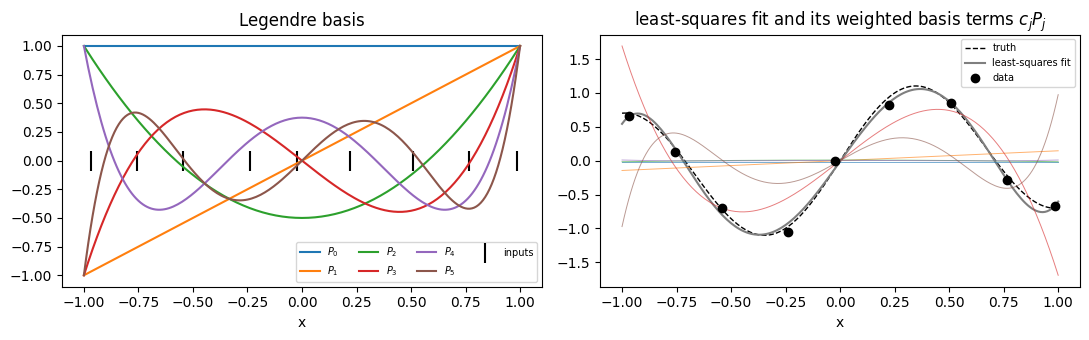

In [4]:
pce = PolynomialChaosExpansion(num_inputs=1, num_outputs=1, degree=DEGREE)
P = pce.num_terms  # 6 coefficients
DIM = P + 1        # + one noise parameter (below)

with torch.no_grad():
    basis = pce(X_BAND, torch.eye(P))[:, :, 0]       # (P, 201): row j is P_j on the grid
    Phi = pce(x_train, torch.eye(P))[:, :, 0].T      # (n, P) design matrix

c_ls = torch.linalg.lstsq(Phi, y_train).solution
sigma_hat = ((y_train - Phi @ c_ls).pow(2).sum() / (N_TRAIN - P)).sqrt().item()
print(f"n = {N_TRAIN} observations, p = {P} coefficients -> {N_TRAIN - P} residual degrees of freedom")
print("least-squares coefficients:", c_ls.numpy().round(3))
print(f"classical residual estimate of sigma: {sigma_hat:.3f} (true {SIGMA_TRUE})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for j in range(P):
    axes[0].plot(XB, basis[j], label=f"$P_{j}$")
axes[0].scatter(x_train[:, 0], torch.zeros(N_TRAIN), marker="|", color="k", s=200, label="inputs")
axes[0].set_title("Legendre basis")
axes[0].legend(fontsize=7, ncol=4)
with torch.no_grad():
    f_ls = pce(X_BAND, c_ls[None])[0, :, 0]
axes[1].plot(XB, truth(XB), "k--", lw=1, label="truth")
axes[1].plot(XB, f_ls, color="tab:gray", label="least-squares fit")
for j in range(P):
    axes[1].plot(XB, c_ls[j] * basis[j], lw=0.7, alpha=0.6)
axes[1].scatter(x_train[:, 0], y_train, color="k", zorder=3, label="data")
axes[1].set_title("least-squares fit and its weighted basis terms $c_j P_j$")
axes[1].legend(fontsize=7)
for ax in axes:
    ax.set_xlabel("x")
plt.tight_layout()

## 3. Likelihood and prior

The parameter vector is $\theta = (c_0, \dots, c_5, u) \in \mathbb{R}^7$, with
the noise level parameterized as $\log\sigma = \log 0.3 + u$.

* **Likelihood:** $y_i \mid \theta \sim N\big(\textstyle\sum_j c_j P_j(x_i), \sigma^2\big)$,
  so $-\log p(y\mid\theta) = \tfrac{1}{2\sigma^2}\lVert y - \Phi c\rVert^2 + n\log\sigma + \tfrac{n}{2}\log 2\pi$.
  The $n\log\sigma$ term matters: without it $\sigma$ would run off to infinity.
* **Prior:** $\theta \sim N(0, I)$. For the coefficients that is a unit
  Gaussian; for the noise it is a log-normal with median 0.3 (deliberately
  three times the truth) and one e-fold of spread. Putting $u$ on the same
  unit scale lets every family use `IIDGaussianPrior()`.

The functions below take a batch `theta` of shape `(S, 7)` and return `(S,)`.

In [5]:
MU_LOGSIG = math.log(0.3)


def log_sigma_of(theta):
    return MU_LOGSIG + theta[:, -1]


def neg_log_lik(theta):
    c, ls = theta[:, :P], log_sigma_of(theta)
    r = y_train - c @ Phi.T
    return 0.5 * (r**2).sum(-1) * torch.exp(-2 * ls) + N_TRAIN * ls + 0.5 * N_TRAIN * LOG2PI


def log_prior(theta):
    return -0.5 * (theta**2).sum(-1) - 0.5 * theta.shape[-1] * LOG2PI


def log_joint(theta):
    return -neg_log_lik(theta) + log_prior(theta)


def functions_of(theta, x=X_BAND):
    # pushforward: parameter samples -> PCE function values, shape (S, len(x))
    with torch.no_grad():
        return pce(x, theta[:, :P])[..., 0]


def predictive_draws(theta, x=X_BAND, seed=11):
    # posterior-predictive draws y* = f(x) + sigma * eps, one per parameter sample
    g = torch.Generator().manual_seed(seed)
    f = functions_of(theta, x)
    return f + log_sigma_of(theta).exp()[:, None] * torch.randn(f.shape, generator=g)

### What the prior believes: the prior pushforward

A prior on coefficients is hard to judge by itself; what matters is the
distribution it induces on *functions* and on *observations*. Below:
prior draws of the PCE (left), the prior predictive band including noise
(middle), and the prior on $\sigma$ (right). The prior is broad but not
absurd: functions of order one, noise between a few percent and one.

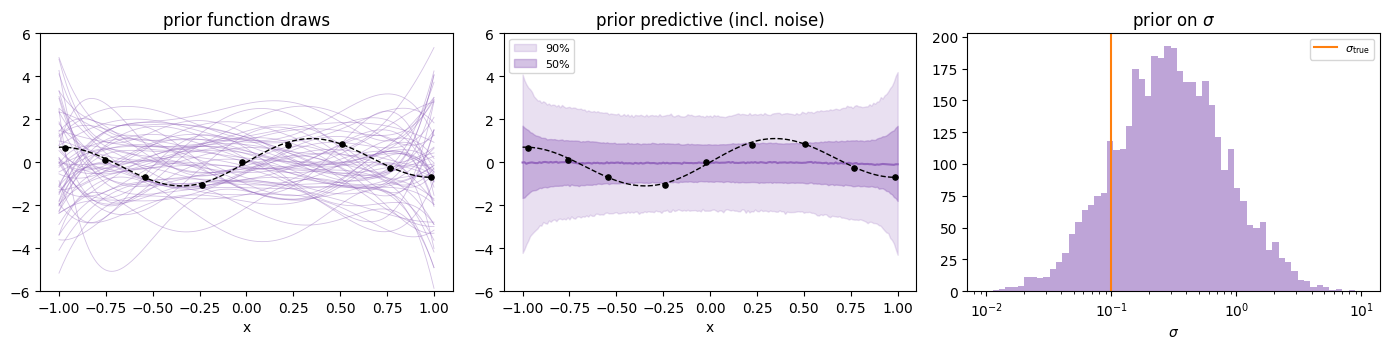

In [6]:
torch.manual_seed(0)
theta_prior = torch.randn(4000, DIM)
f_prior = functions_of(theta_prior)
y_prior = predictive_draws(theta_prior)

fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
for k in range(60):
    axes[0].plot(XB, f_prior[k], color="tab:purple", lw=0.6, alpha=0.4)
axes[0].set_title("prior function draws")
q = torch.quantile(y_prior, torch.tensor([0.05, 0.25, 0.5, 0.75, 0.95]), dim=0)
axes[1].fill_between(XB, q[0], q[4], color="tab:purple", alpha=0.2, label="90%")
axes[1].fill_between(XB, q[1], q[3], color="tab:purple", alpha=0.4, label="50%")
axes[1].plot(XB, q[2], color="tab:purple")
axes[1].set_title("prior predictive (incl. noise)")
for ax in axes[:2]:
    ax.plot(XB, truth(XB), "k--", lw=1)
    ax.scatter(x_train[:, 0], y_train, color="k", s=14, zorder=5)
    ax.set_xlabel("x")
    ax.set_ylim(-6, 6)
axes[1].legend(fontsize=8)
axes[2].hist(log_sigma_of(theta_prior).exp().numpy(), bins=np.logspace(-2, 1, 60), color="tab:purple", alpha=0.6)
axes[2].axvline(SIGMA_TRUE, color="tab:orange", label=r"$\sigma_\mathrm{true}$")
axes[2].set_xscale("log")
axes[2].set_xlabel(r"$\sigma$")
axes[2].set_title(r"prior on $\sigma$")
axes[2].legend(fontsize=8)
plt.tight_layout()

## 4. Warm-up: if we knew $\sigma$, the posterior would be Gaussian

Fix $\sigma$. The model is linear in $c$ with a Gaussian prior and
likelihood, so the posterior is the textbook conjugate result
$$c \mid y, \sigma \sim N\big(m(\sigma), C(\sigma)\big),\quad
C(\sigma) = \big(\Phi^\top\Phi/\sigma^2 + I\big)^{-1},\quad
m(\sigma) = C(\sigma)\,\Phi^\top y/\sigma^2.$$
A full-covariance Gaussian represents this exactly. The catch is that
**every part of it depends on $\sigma$**: below are the posteriors for three
plausible noise levels. Small $\sigma$ pins the fit to the data; large
$\sigma$ lets the prior pull the coefficients toward zero and widens the
band. With nine points we cannot tell these apart very well, so we must
average over $\sigma$, and that average is no longer Gaussian.

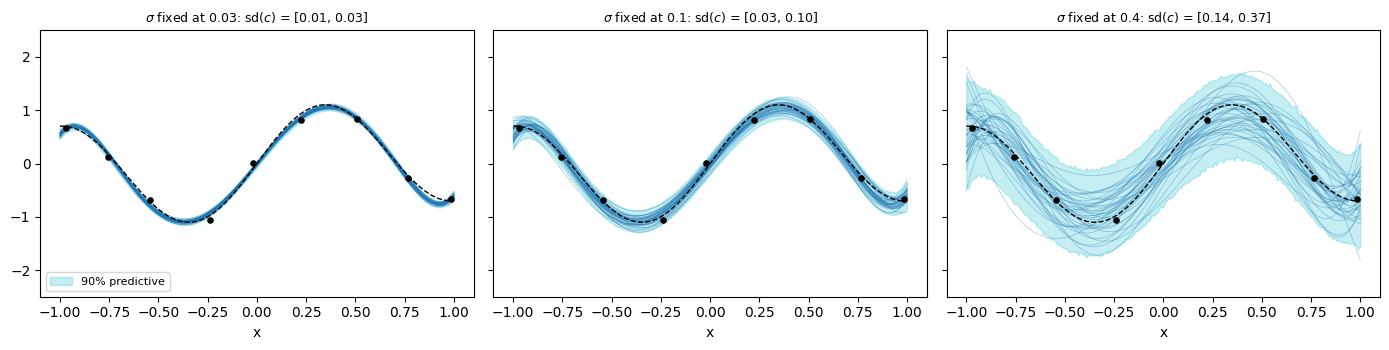

In [7]:
def conditional_c(u):
    # mean (M, P) and covariance (M, P, P) of c | u, y, for a batch of u values
    s2 = torch.exp(2 * (MU_LOGSIG + u))
    prec = (Phi.T @ Phi)[None] / s2[:, None, None] + torch.eye(P)[None]
    cov = torch.linalg.inv(prec)
    mean = (cov @ (Phi.T @ y_train / s2[:, None])[..., None])[..., 0]
    return mean, cov


fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, sig in zip(axes, [0.03, 0.1, 0.4]):
    u = torch.tensor([math.log(sig) - MU_LOGSIG])
    m, C = conditional_c(u)
    torch.manual_seed(1)
    c = m[0] + torch.randn(2000, P) @ torch.linalg.cholesky(C[0]).T
    th = torch.cat([c, u.expand(2000)[:, None]], 1)
    f = functions_of(th)
    yq = torch.quantile(predictive_draws(th), torch.tensor([0.05, 0.95]), dim=0)
    ax.fill_between(XB, yq[0], yq[1], color="tab:cyan", alpha=0.25, label="90% predictive")
    for k in range(40):
        ax.plot(XB, f[k], color="tab:blue", lw=0.5, alpha=0.4)
    ax.plot(XB, truth(XB), "k--", lw=1)
    ax.scatter(x_train[:, 0], y_train, color="k", s=14, zorder=5)
    sd = C[0].diagonal().sqrt().numpy()
    ax.set_title(rf"$\sigma$ fixed at {sig}: sd$(c)$ = [{sd.min():.2f}, {sd.max():.2f}]", fontsize=9)
    ax.set_xlabel("x")
axes[0].set_ylim(-2.5, 2.5)
axes[0].legend(fontsize=8, loc="lower left")
plt.tight_layout()

## 5. Unknown $\sigma$: the exact joint posterior

Now treat $u$ (that is, $\log\sigma$) as unknown. Conjugacy still does most
of the work. Integrating $c$ out analytically gives the marginal likelihood
of the noise level,
$$p(y \mid u) = N\big(y;\ 0,\ \Phi\Phi^\top + \sigma^2 I\big),$$
so the posterior of $u$ is a 1-D density we can tabulate on a fine grid,
and $c \mid u, y$ is the Gaussian from the warm-up. This gives the
normalizer $\log Z$, the exact log density at any $\theta$, and exact
i.i.d. samples (draw $u$ from the grid, then $c \mid u$). It is the ground
truth for the rest of the notebook.

log Z = -9.2272   (grid mass check: 1.000000)
exact entropy H[p] = -4.5210 nats
sigma | y: median 0.156, 90% interval [0.084, 0.376]  (true 0.1)


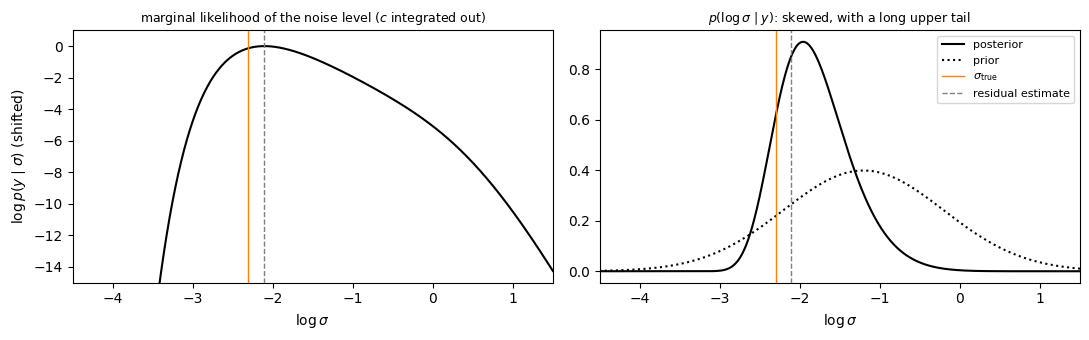

In [8]:
def log_evidence_given_u(u):
    K = Phi @ Phi.T
    s2 = torch.exp(2 * (MU_LOGSIG + u))
    cov = K[None] + s2[:, None, None] * torch.eye(N_TRAIN)[None]
    return torch.distributions.MultivariateNormal(torch.zeros(N_TRAIN), cov).log_prob(y_train)


u_grid = torch.linspace(-8, 8, 4001)
du = (u_grid[1] - u_grid[0]).item()
log_ev = log_evidence_given_u(u_grid)
_lm = log_ev - 0.5 * u_grid**2 - 0.5 * LOG2PI
logZ = (torch.logsumexp(_lm, 0) + math.log(du)).item()
log_post_u = _lm - logZ  # exact log p(u | y) on the grid
ls_grid = MU_LOGSIG + u_grid


def exact_samples(num, seed):
    g = torch.Generator().manual_seed(seed)
    idx = torch.multinomial(log_post_u.exp(), num, replacement=True, generator=g)
    us = u_grid[idx] + du * (torch.rand(num, generator=g) - 0.5)
    m, C = conditional_c(us)
    c = m + (torch.linalg.cholesky(C) @ torch.randn(num, P, 1, generator=g))[..., 0]
    return torch.cat([c, us[:, None]], -1)


N_EXACT = 100_000
theta_exact = exact_samples(N_EXACT, seed=0)
H_exact = -(log_joint(theta_exact) - logZ).mean().item()  # exact entropy, MC over exact samples
exact_mean, exact_cov = theta_exact.mean(0), torch.cov(theta_exact.T)
print(f"log Z = {logZ:.4f}   (grid mass check: {(log_post_u.exp().sum() * du).item():.6f})")
print(f"exact entropy H[p] = {H_exact:.4f} nats")
sig_q = torch.quantile(log_sigma_of(theta_exact).exp(), torch.tensor([0.05, 0.5, 0.95]))
print(f"sigma | y: median {sig_q[1]:.3f}, 90% interval [{sig_q[0]:.3f}, {sig_q[2]:.3f}]  (true {SIGMA_TRUE})")

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].plot(ls_grid, log_ev - log_ev.max(), "k")
axes[0].set_ylim(-15, 1)
axes[0].set_ylabel(r"$\log p(y\mid\sigma)$ (shifted)")
axes[0].set_title(r"marginal likelihood of the noise level ($c$ integrated out)", fontsize=9)
axes[1].plot(ls_grid, log_post_u.exp(), "k", label="posterior")
axes[1].plot(ls_grid, torch.exp(-0.5 * u_grid**2 - 0.5 * LOG2PI), "k:", label="prior")
axes[1].set_title(r"$p(\log\sigma \mid y)$: skewed, with a long upper tail", fontsize=9)
for ax in axes:
    ax.axvline(math.log(SIGMA_TRUE), color="tab:orange", lw=1, label=r"$\sigma_\mathrm{true}$")
    ax.axvline(math.log(sigma_hat), color="tab:gray", lw=1, ls="--", label="residual estimate")
    ax.set_xlim(-4.5, 1.5)
    ax.set_xlabel(r"$\log\sigma$")
axes[1].legend(fontsize=8)
plt.tight_layout()

### How the coefficients depend on the noise level

Plotting $m_j(u)$ and $\sqrt{C_{jj}(u)}$ against $\log\sigma$ shows the two
mechanisms behind the non-Gaussian shape. The **spread grows** with
$\sigma$ (roughly proportionally while the data dominate, then levelling
off at the prior width): that is the *funnel*. The **mean moves**
nonlinearly toward zero as $\sigma$ grows, because the prior wins over the
data for the poorly determined coefficients: that is the *bend*. A
Gaussian has a constant conditional spread and a linear conditional mean.
The shaded region is the central 98% of $p(\log\sigma\mid y)$.

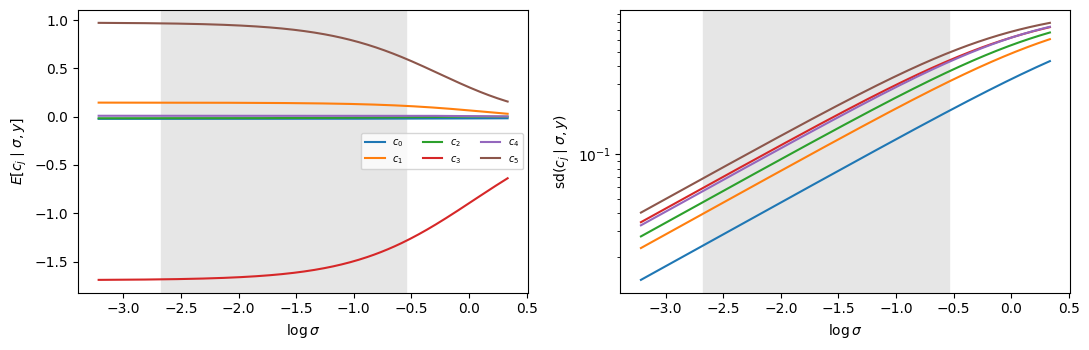

In [9]:
u_lo, u_hi = torch.quantile(theta_exact[:, -1], torch.tensor([0.0005, 0.9995])).tolist()
U_PLOT = torch.linspace(u_lo - 0.3, u_hi + 0.3, 240)
LS_PLOT = MU_LOGSIG + U_PLOT
m_plot, C_plot = conditional_c(U_PLOT)
log_pu_plot = log_evidence_given_u(U_PLOT) - 0.5 * U_PLOT**2 - 0.5 * LOG2PI - logZ
ls01, ls99 = torch.quantile(log_sigma_of(theta_exact), torch.tensor([0.01, 0.99])).tolist()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for j in range(P):
    axes[0].plot(LS_PLOT, m_plot[:, j], label=f"$c_{j}$")
    axes[1].plot(LS_PLOT, C_plot[:, j, j].sqrt(), label=f"$c_{j}$")
axes[0].set_ylabel(r"$E[c_j \mid \sigma, y]$")
axes[1].set_ylabel(r"sd$(c_j \mid \sigma, y)$")
axes[1].set_yscale("log")
for ax in axes:
    ax.axvspan(ls01, ls99, color="0.9", zorder=0)
    ax.set_xlabel(r"$\log\sigma$")
axes[0].legend(fontsize=7, ncol=3)
plt.tight_layout()

### The funnel, slice by slice

Exact joint density of each $(c_j, \log\sigma)$ pair,
$p(c_j, u \mid y) = p(u \mid y)\, N(c_j; m_j(u), C_{jj}(u))$, with contours
enclosing 50/90/99% of the mass and the conditional mean dashed. The
*funnel ratio* in each label is the conditional sd at the 90% quantile of
$\sigma$ over that at the 10% quantile; it is exactly 1 for any Gaussian.
The slice with the largest ratio is used for the comparison plots later.

exact funnel ratio per coefficient: [3.19 3.15 3.13 3.08 3.11 3.06]
slice used in later comparisons: (c_0, log sigma)


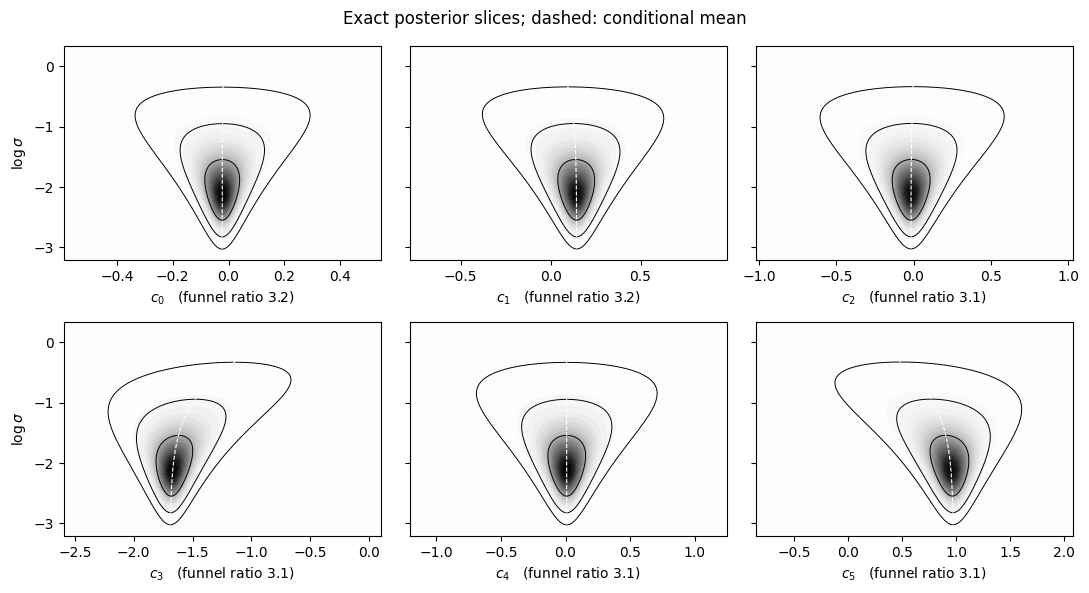

In [10]:
def joint_density_grid(j, nc=240):
    lo, hi = torch.quantile(theta_exact[:, j], torch.tensor([0.0005, 0.9995])).tolist()
    pad = 0.15 * (hi - lo)
    c = torch.linspace(lo - pad, hi + pad, nc)
    sd = C_plot[:, j, j].sqrt()
    logd = (log_pu_plot[:, None] - 0.5 * ((c[None] - m_plot[:, j, None]) / sd[:, None]) ** 2
            - torch.log(sd[:, None]) - 0.5 * LOG2PI)
    return c, logd.exp()  # c-axis, density over (u, c)


def hpd_levels(dens, masses=(0.99, 0.9, 0.5)):
    d = dens.flatten().sort(descending=True).values
    cum = d.cumsum(0) / d.sum()
    return [d[(cum >= m).nonzero()[0, 0]].item() for m in masses]


q10, q90 = torch.quantile(theta_exact[:, -1], torch.tensor([0.1, 0.9]))
funnel_ratio = (conditional_c(q90[None])[1][0].diagonal() / conditional_c(q10[None])[1][0].diagonal()).sqrt()
J_SHOW = int(funnel_ratio.argmax())
print("exact funnel ratio per coefficient:", funnel_ratio.numpy().round(2))
print(f"slice used in later comparisons: (c_{J_SHOW}, log sigma)")

C_AX, DENS = joint_density_grid(J_SHOW)
LEVELS = hpd_levels(DENS)


def exact_contours(ax, filled=False):
    if filled:
        ax.contourf(C_AX, LS_PLOT, DENS, levels=30, cmap="Greys")
    ax.contour(C_AX, LS_PLOT, DENS, levels=LEVELS, colors="k", linewidths=0.7)


fig, axes = plt.subplots(2, 3, figsize=(11, 6), sharey=True)
for j, ax in enumerate(axes.flat):
    c_ax, dens = joint_density_grid(j)
    ax.contourf(c_ax, LS_PLOT, dens, levels=30, cmap="Greys")
    ax.contour(c_ax, LS_PLOT, dens, levels=hpd_levels(dens), colors="k", linewidths=0.7)
    ax.plot(m_plot[:, j], LS_PLOT, "w--", lw=0.8)
    ax.set_xlabel(f"$c_{j}$   (funnel ratio {funnel_ratio[j]:.1f})")
for ax in axes[:, 0]:
    ax.set_ylabel(r"$\log\sigma$")
fig.suptitle("Exact posterior slices; dashed: conditional mean")
plt.tight_layout()

### All seven dimensions at once: a corner plot

Pairwise scatter of 1500 exact samples (lower triangle) and marginal
histograms (diagonal). The last row is the important one: every
coefficient fans out as $\log\sigma$ grows. The coefficient-coefficient
panels look nearly elliptical; the non-Gaussianity lives in the coupling
to the noise level. `corner()` is reused later to overlay each family on
the exact posterior.

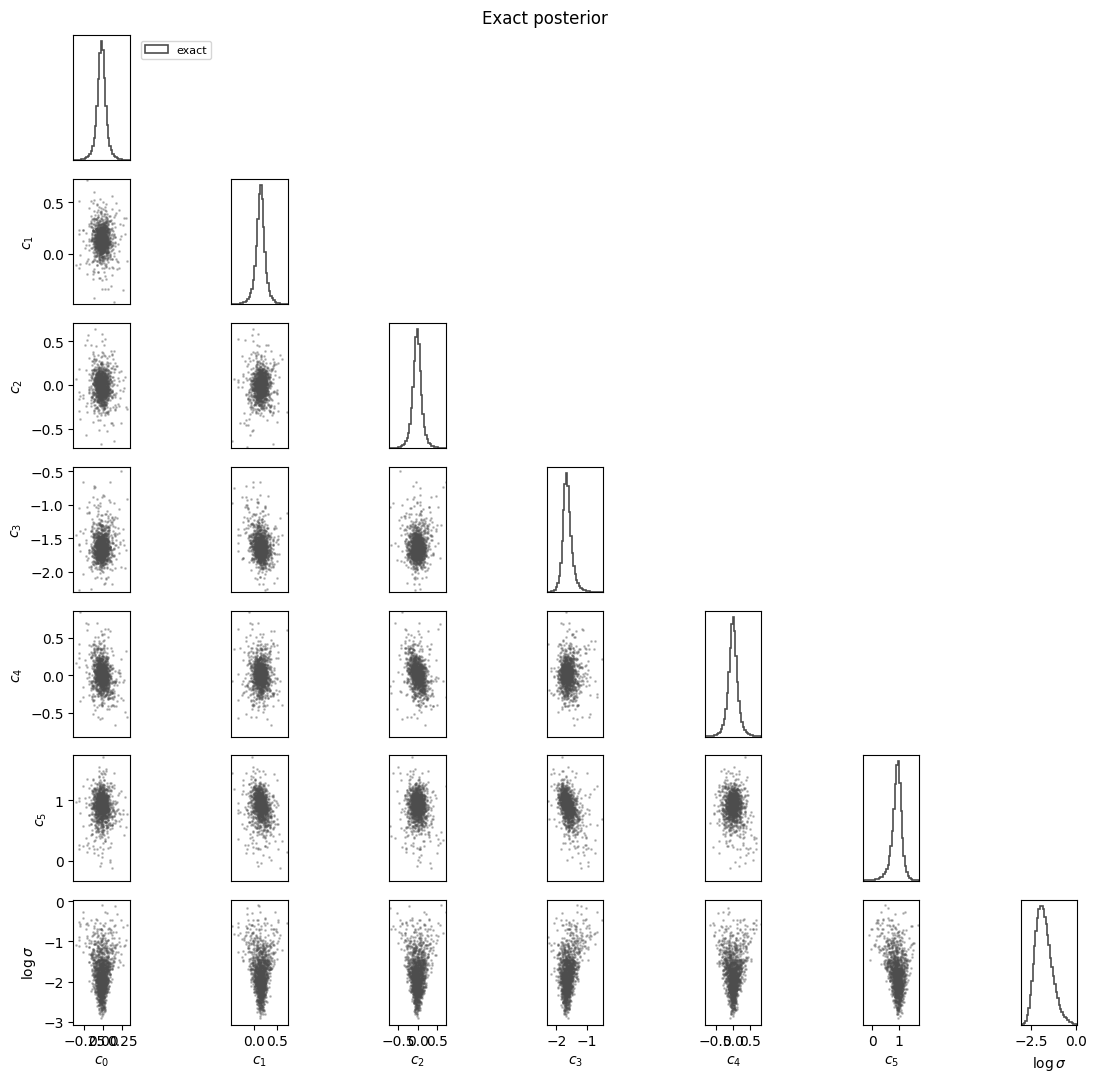

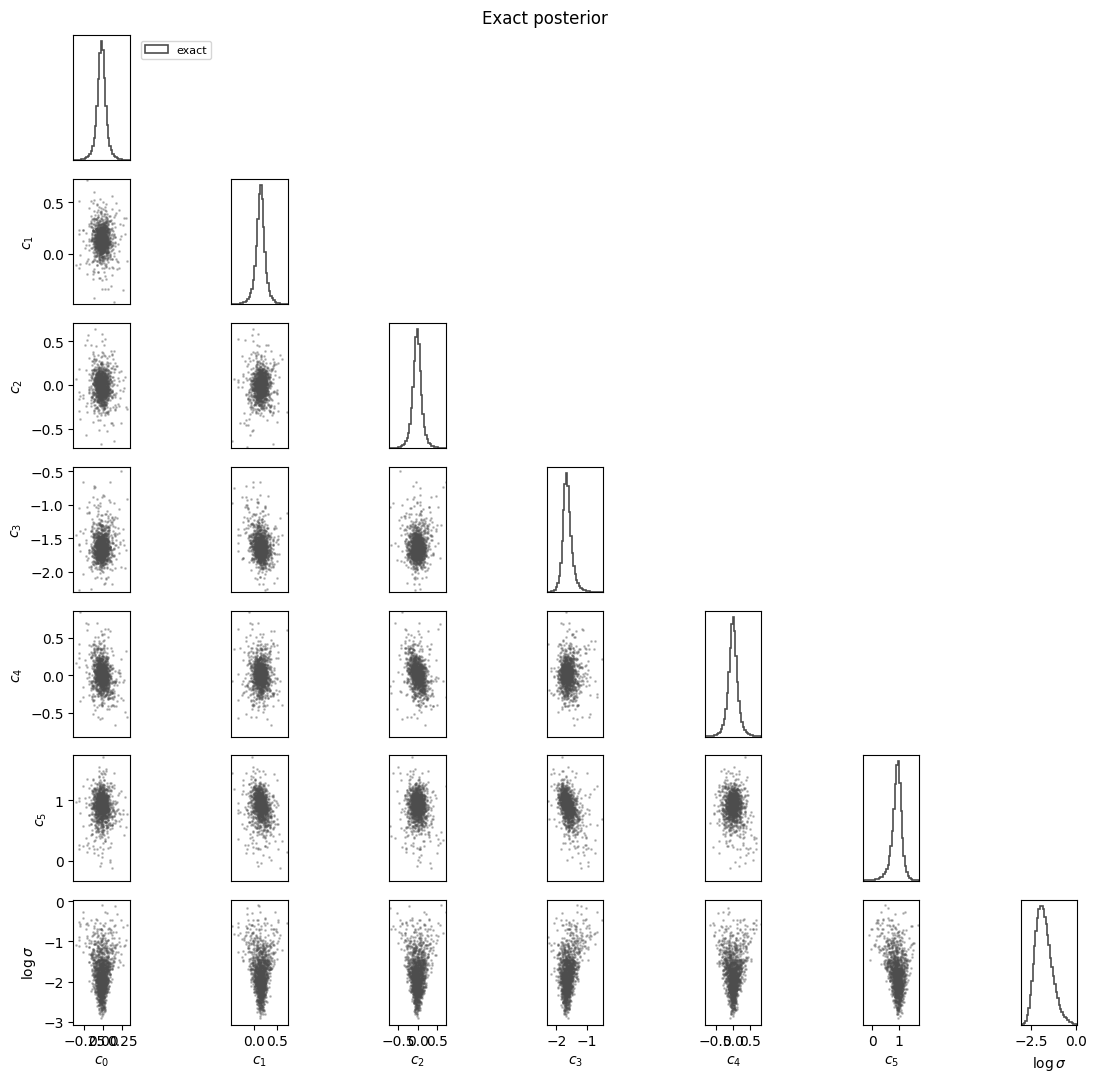

In [11]:
NAMES = [f"$c_{j}$" for j in range(P)] + [r"$\log\sigma$"]


def to_display(th):
    return torch.cat([th[:, :P], log_sigma_of(th)[:, None]], 1)


_ref = to_display(theta_exact)
CORNER_LIMS = []
for i in range(DIM):
    lo, hi = torch.quantile(_ref[:, i], torch.tensor([0.002, 0.998])).tolist()
    CORNER_LIMS.append((lo - 0.1 * (hi - lo), hi + 0.1 * (hi - lo)))


def corner(sample_sets, n=1500, title=None):
    # sample_sets: list of (label, theta, color); first entry drawn underneath
    fig, axes = plt.subplots(DIM, DIM, figsize=(11, 11))
    for i in range(DIM):
        for j in range(DIM):
            ax = axes[i, j]
            if j > i:
                ax.axis("off")
                continue
            for label, th, color in sample_sets:
                d = to_display(th)
                if i == j:
                    ax.hist(d[:, i].numpy(), bins=np.linspace(*CORNER_LIMS[i], 40), density=True,
                            histtype="step", color=color, lw=1.2, label=label)
                else:
                    ax.scatter(d[:n, j], d[:n, i], s=1, alpha=0.3, color=color, rasterized=True)
            ax.set_xlim(CORNER_LIMS[j])
            if i != j:
                ax.set_ylim(CORNER_LIMS[i])
            ax.set_yticks([]) if (j > 0 or i == 0) else ax.set_ylabel(NAMES[i])
            ax.set_xticks([]) if i < DIM - 1 else ax.set_xlabel(NAMES[j])
    axes[0, 0].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.1, 1.0))
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    return fig


corner([("exact", theta_exact, FAMILY_COLORS["exact"])], title="Exact posterior")

### Pushing the posterior forward: functions and predictions

Each posterior sample $\theta$ is a function $f_\theta(x)$ plus a noise
level. Colouring the function draws by their own $\sigma$ shows the
funnel in function space: draws with small $\sigma$ thread through the
data; draws with large $\sigma$ are pulled toward the prior and wander
away from the data, especially between points and at the edges. The right
panel is the exact posterior predictive for a new observation $y^\ast$.

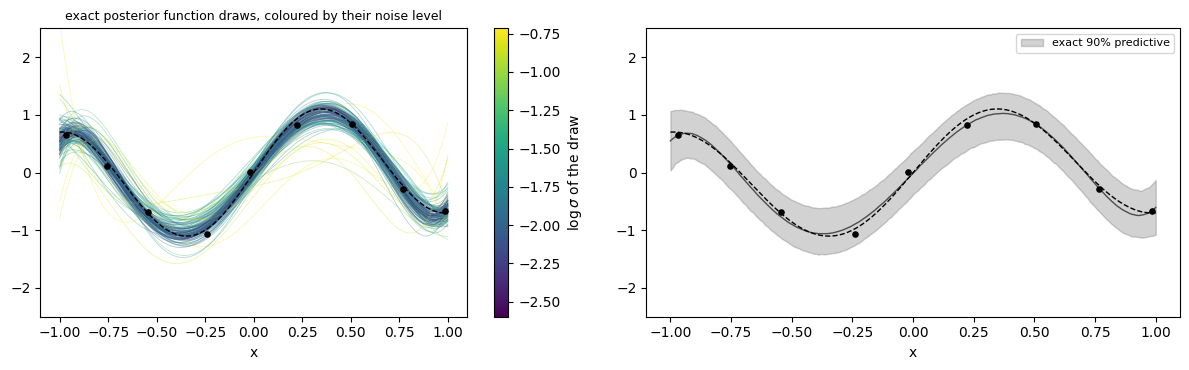

In [12]:
SIG_NORM = plt.Normalize(*torch.quantile(log_sigma_of(theta_exact), torch.tensor([0.02, 0.98])).tolist())


def plot_function_draws(ax, th, n=120, color=None, by_sigma=False, alpha=0.35):
    f = functions_of(th[:n])
    ls = log_sigma_of(th[:n])
    for k in range(f.shape[0]):
        col = plt.cm.viridis(SIG_NORM(ls[k].item())) if by_sigma else color
        ax.plot(XB, f[k], color=col, lw=0.6, alpha=alpha)
    ax.plot(XB, truth(XB), "k--", lw=1)
    ax.scatter(x_train[:, 0], y_train, color="k", s=14, zorder=5)
    ax.set_ylim(-2.5, 2.5)
    ax.set_xlabel("x")


def sigma_colorbar(fig, ax):
    sm = plt.cm.ScalarMappable(norm=SIG_NORM, cmap="viridis")
    fig.colorbar(sm, ax=ax, label=r"$\log\sigma$ of the draw")


def plot_band(ax, th, color, label=None, alpha=0.25):
    q = torch.quantile(predictive_draws(th), torch.tensor([0.05, 0.5, 0.95]), dim=0)
    ax.fill_between(XB, q[0], q[2], color=color, alpha=alpha, label=label)
    ax.plot(XB, q[1], color=color, lw=1)


fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
plot_function_draws(axes[0], theta_exact, by_sigma=True)
sigma_colorbar(fig, axes[0])
axes[0].set_title("exact posterior function draws, coloured by their noise level", fontsize=9)
plot_band(axes[1], theta_exact[:20_000], FAMILY_COLORS["exact"], label="exact 90% predictive")
axes[1].plot(XB, truth(XB), "k--", lw=1)
axes[1].scatter(x_train[:, 0], y_train, color="k", s=14, zorder=5)
axes[1].set_ylim(-2.5, 2.5)
axes[1].set_xlabel("x")
axes[1].legend(fontsize=8)
plt.tight_layout()

## 6. Gaussian variational families

Variational inference picks $q$ from a family by minimizing
$\mathrm{KL}(q\,\|\,p(\theta\mid y))$, which is the same as minimizing the
loss
$$\mathcal{L}(q) = \mathbb{E}_q\big[-\log p(y\mid\theta)\big] + \mathrm{KL}(q\,\|\,\text{prior})
= \mathrm{KL}\big(q\,\|\,p(\theta\mid y)\big) - \log Z.$$
Since we know $\log Z$, **loss $+\log Z$ is the KL to the exact posterior**,
which we use as a running diagnostic.

### 6a. The best a Gaussian can do

Before training anything with `pypolymix`, fit the best mean-field and the
best full-covariance Gaussian *directly* against the exact log density
(reparameterized gradients, fixed base samples, 3000 Adam steps), and
evaluate their KL on 200k fresh samples. No training procedure can push a
Gaussian below these *family ceilings*.

In [13]:
def fit_best_gaussian(diag, steps=3000, nbase=8192, seed=0):
    g = torch.Generator().manual_seed(seed)
    eps = torch.randn(nbase, DIM, generator=g)
    mu = exact_mean.clone().requires_grad_(True)
    L0 = torch.linalg.cholesky(exact_cov)
    raw = (L0.diagonal().log() if diag else L0).clone().requires_grad_(True)
    opt = torch.optim.Adam([mu, raw], lr=0.01)

    def scale():
        if diag:
            return torch.diag(raw.exp())
        L = torch.tril(raw)
        return L - torch.diag(L.diagonal()) + torch.diag(L.diagonal().abs() + 1e-12)

    def kl(e):
        S = scale()
        H = 0.5 * DIM * (1 + LOG2PI) + S.diagonal().log().sum()
        return (-log_joint(mu + e @ S.T)).mean() - H + logZ

    for _ in range(steps):
        opt.zero_grad()
        loss = kl(eps)
        loss.backward()
        opt.step()
    with torch.no_grad():
        return {"kl": kl(torch.randn(200_000, DIM, generator=g)).item(),
                "mean": mu.detach(), "scale_tril": scale().detach()}


ceiling = cache.get("ceilings_v1", lambda: {"iid": fit_best_gaussian(True), "full": fit_best_gaussian(False)})
print(f"best mean-field       KL(q||p) = {ceiling['iid']['kl']:.3f} nats")
print(f"best full-covariance  KL(q||p) = {ceiling['full']['kl']:.3f} nats")

[cache miss] ceilings_v1  ->  ceilings_v1.pt  (computed in 13.2s)
best mean-field       KL(q||p) = 1.040 nats
best full-covariance  KL(q||p) = 0.599 nats


### 6b. Training with `pypolymix`

A `ParameterGroup` is a distribution over a flat parameter vector with two
methods that matter here: `sample_parameters(S)` returns reparameterized
samples of shape `(S, 7)`, and `distribution_loss()` returns its
$\mathrm{KL}(q\,\|\,\text{prior})$ term.

* `IIDGaussianGroup`: mean-field, analytic KL to the prior.
* `GaussianGroup`: full covariance via a Cholesky factor, Monte Carlo KL.

The loop is the same for every family: sample, push the samples through
the likelihood, add the distribution loss, step. `to_theta` maps the
group's samples to $\theta$; it is the identity here and an affine map for
the Langevin group later. 4000 epochs, 64 samples, Adam with a one-cycle
schedule.

In [14]:
def train_group(group, to_theta, *, num_epochs, num_samples, lr, max_lr_mult, clip=None, seed=0):
    torch.manual_seed(seed)
    opt = torch.optim.Adam(group.parameters(), lr=lr)
    sched = OneCycleLR(opt, max_lr=max_lr_mult * lr, total_steps=num_epochs)
    hist = np.zeros((num_epochs, 2))
    for ep in range(num_epochs):
        opt.zero_grad()
        nll = neg_log_lik(to_theta(group.sample_parameters(num_samples))).mean()
        kl = group.distribution_loss()
        (nll + kl).backward()
        if clip is not None:
            torch.nn.utils.clip_grad_norm_(group.parameters(), clip)
        opt.step()
        sched.step()
        hist[ep] = nll.item(), kl.item()
    return hist


def identity(theta):
    return theta


def make_gaussian(kind, seed=0):
    torch.manual_seed(seed)
    if kind == "iid":
        return IIDGaussianGroup("theta", DIM, prior=IIDGaussianPrior())
    return GaussianGroup("theta", DIM, prior=IIDGaussianPrior())


def kl_exact_gaussian(group, n=200_000, seed=0):
    torch.manual_seed(seed)
    with torch.no_grad():
        q = group.variational_distribution()
        th = q.sample((n,))
        return (q.log_prob(th) - log_joint(th)).mean().item() + logZ


GAUSS_CFG = dict(num_epochs=4000, num_samples=64, lr=1e-2, max_lr_mult=2.0)
gauss = {}
for kind in ["iid", "full"]:
    def _compute(kind=kind):
        group = make_gaussian(kind)
        t0 = time.time()
        hist = train_group(group, identity, **GAUSS_CFG)
        return {"state_dict": group.state_dict(), "history": hist, "time": time.time() - t0}

    payload = cache.get(f"gauss_{kind}_v1", _compute)
    group = make_gaussian(kind)
    group.load_state_dict(payload["state_dict"])
    gauss[kind] = {"group": group, **payload, "kl": kl_exact_gaussian(group)}
    print(f"{FAMILY_LABELS[kind]:26s} trained in {payload['time']:5.1f}s   exact KL(q||p) = "
          f"{gauss[kind]['kl']:.3f}   (family ceiling {ceiling[kind]['kl']:.3f})")

[cache miss] gauss_iid_v1  ->  gauss_iid_v1.pt  (computed in 3.7s)
Mean-field Gaussian        trained in   3.7s   exact KL(q||p) = 1.922   (family ceiling 1.040)


[cache miss] gauss_full_v1  ->  gauss_full_v1.pt  (computed in 11.6s)
Full-covariance Gaussian   trained in  11.6s   exact KL(q||p) = 0.602   (family ceiling 0.599)


### 6c. What the Gaussians learned

Training curves (loss $+\log Z$, i.e. the running KL), then each Gaussian's
samples over the exact funnel slice, and its function draws coloured by
$\sigma$. The Gaussians can tilt and stretch an ellipse, but the ellipse
has the same width at every $\sigma$: it is too wide where the funnel is
narrow and too narrow where the funnel is wide.

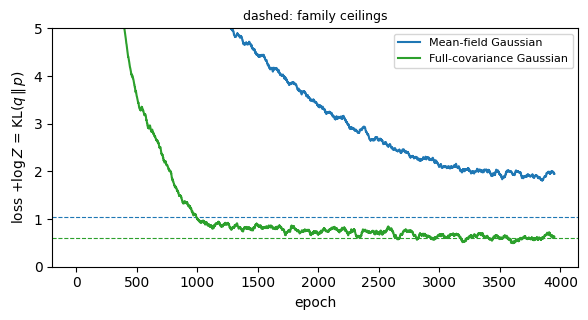

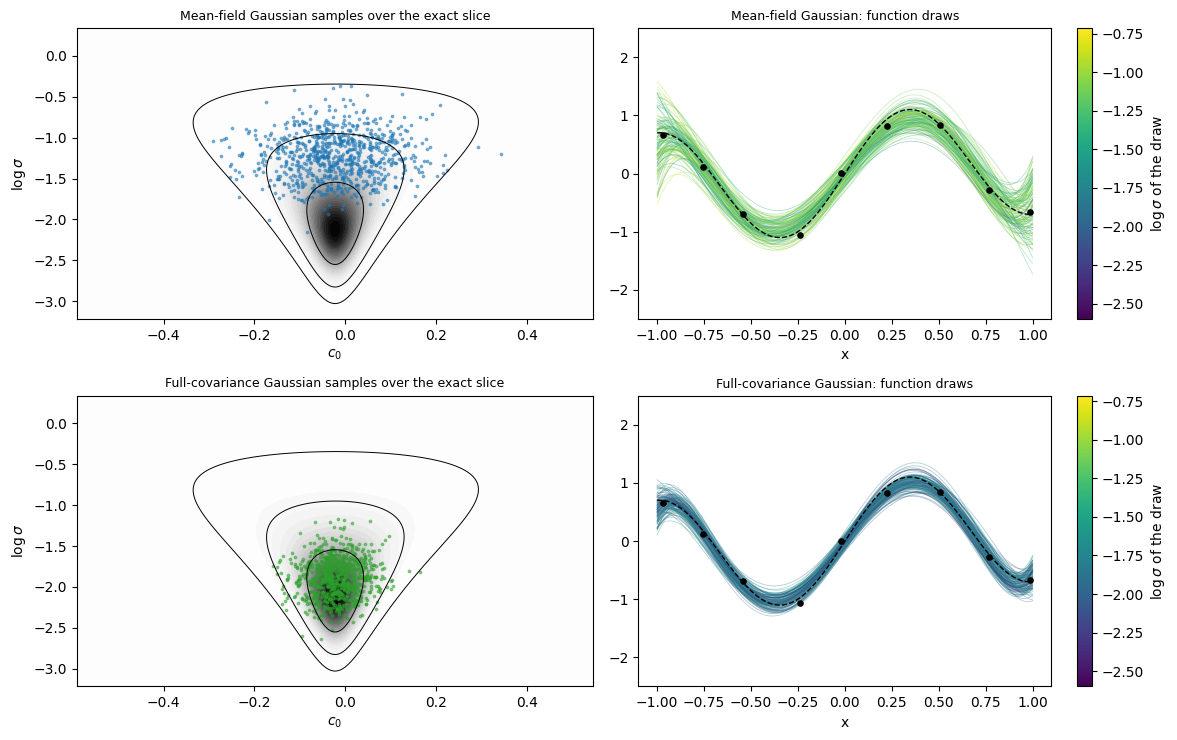

In [15]:
def gauss_samples(kind, n=4000, seed=5):
    torch.manual_seed(seed)
    with torch.no_grad():
        return gauss[kind]["group"].variational_distribution().sample((n,))


W_SMOOTH = 50


def smooth(h):
    return np.convolve(h.sum(1), np.ones(W_SMOOTH) / W_SMOOTH, mode="valid")


fig, ax = plt.subplots(figsize=(6, 3.3))
for kind in ["iid", "full"]:
    ax.plot(smooth(gauss[kind]["history"]) + logZ, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.axhline(ceiling[kind]["kl"], color=FAMILY_COLORS[kind], ls="--", lw=0.8)
ax.set_ylim(0, 5)
ax.set_xlabel("epoch")
ax.set_ylabel(r"loss $+\log Z$ = KL$(q\,\|\,p)$")
ax.set_title("dashed: family ceilings", fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
for row, kind in enumerate(["iid", "full"]):
    th = gauss_samples(kind)
    exact_contours(axes[row, 0], filled=True)
    axes[row, 0].scatter(th[:800, J_SHOW], log_sigma_of(th[:800]), s=3, alpha=0.5, color=FAMILY_COLORS[kind])
    axes[row, 0].set_xlabel(f"$c_{J_SHOW}$")
    axes[row, 0].set_ylabel(r"$\log\sigma$")
    axes[row, 0].set_title(f"{FAMILY_LABELS[kind]} samples over the exact slice", fontsize=9)
    plot_function_draws(axes[row, 1], th, by_sigma=True)
    sigma_colorbar(fig, axes[row, 1])
    axes[row, 1].set_title(f"{FAMILY_LABELS[kind]}: function draws", fontsize=9)
plt.tight_layout()

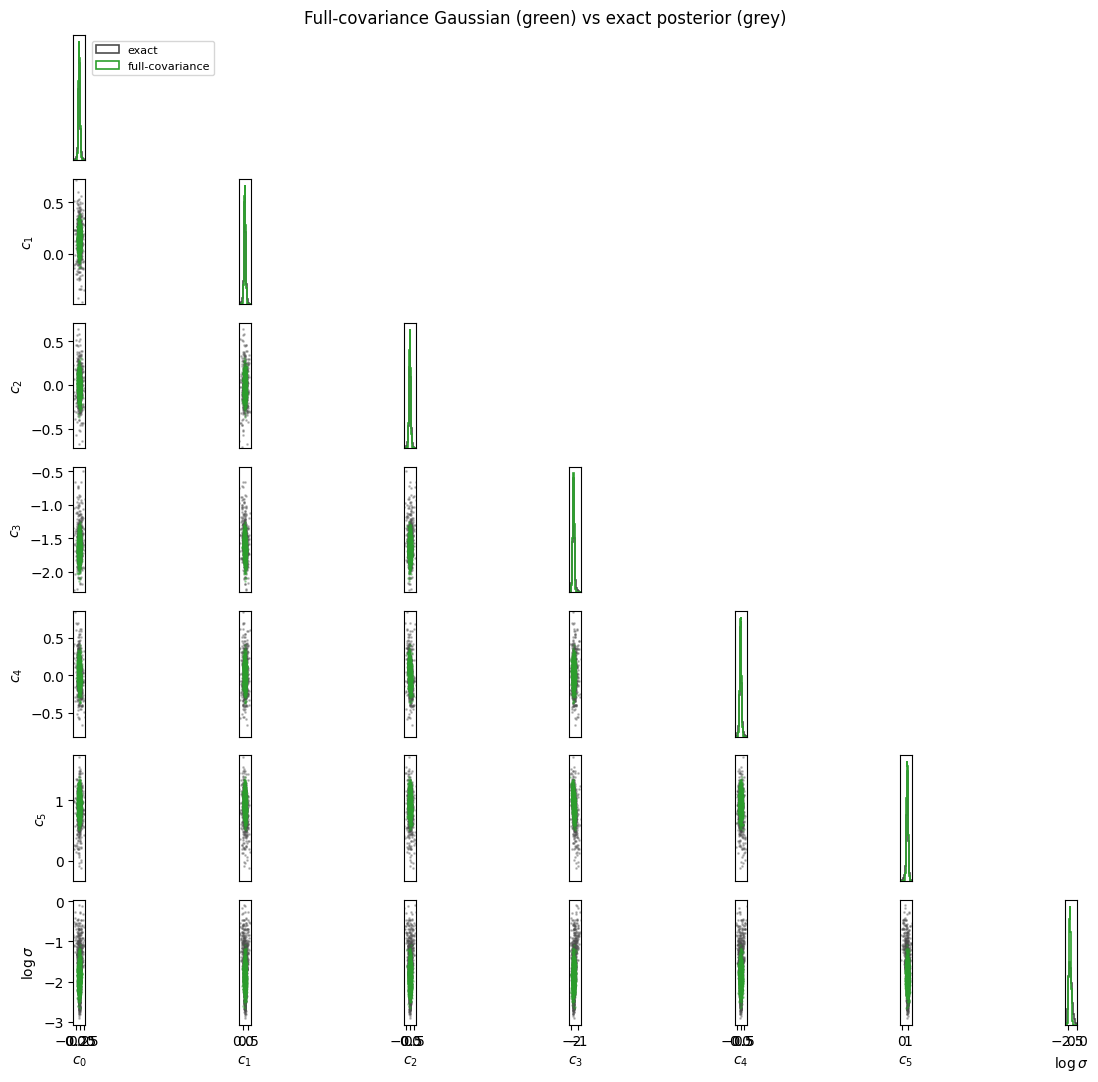

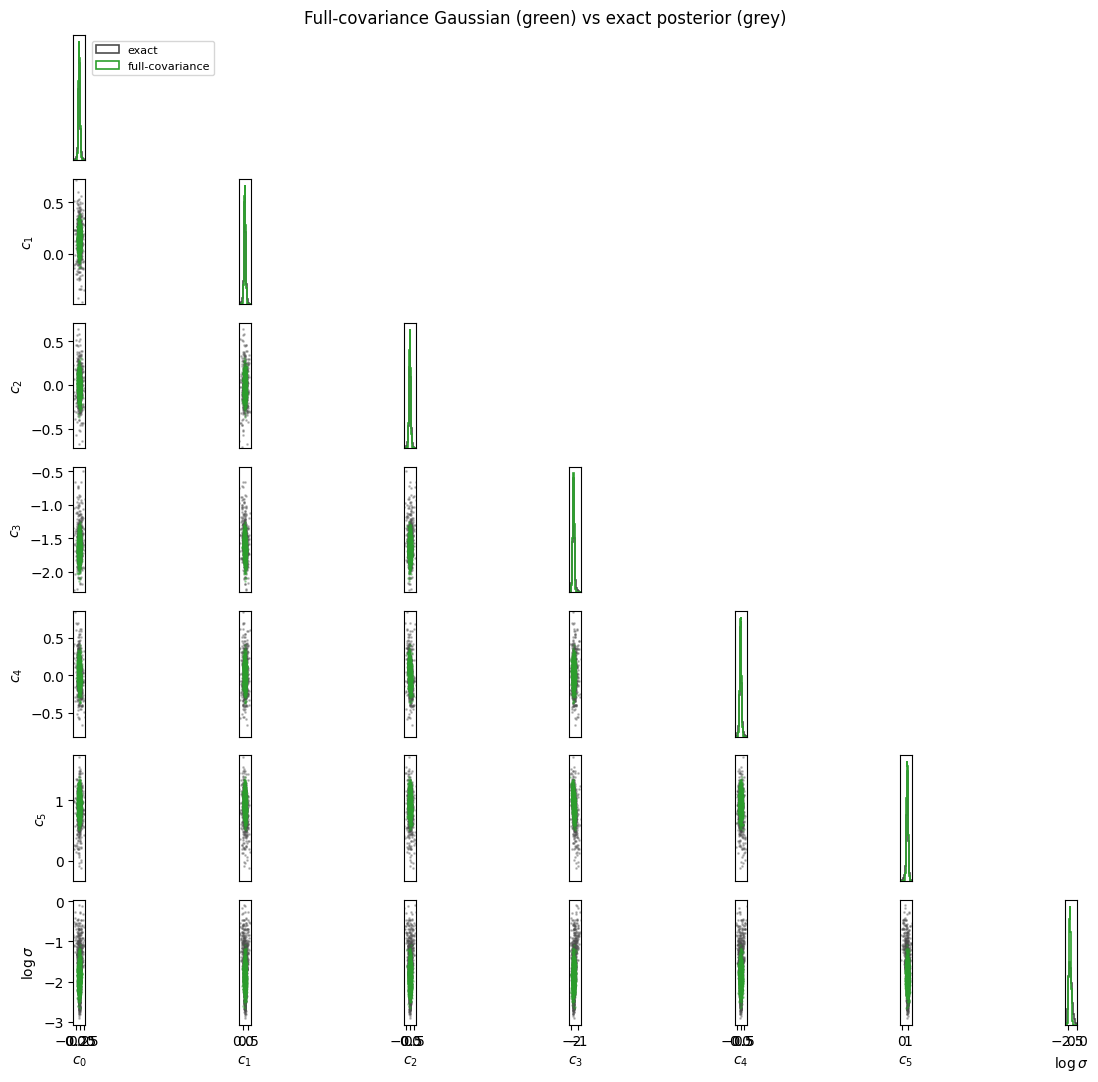

In [16]:
corner([("exact", theta_exact, FAMILY_COLORS["exact"]),
        ("full-covariance", gauss_samples("full"), FAMILY_COLORS["full"])],
       title="Full-covariance Gaussian (green) vs exact posterior (grey)")

## 7. The Langevin generator

`LangevinGroup` does not have a density formula. It defines $q$ *implicitly*,
by a procedure: draw particles $z^{(0)} \sim N(0, \sigma_0^2 I)$, then run
$K$ steps of unadjusted Langevin dynamics
$$z^{(k+1)} = z^{(k)} + h\, s_\phi\big(z^{(k)}\big) + \sqrt{2h}\,\xi^{(k)},\qquad \xi^{(k)} \sim N(0, I),$$
where the drift $s_\phi$ is a small neural network (the *score network*).
The particles after $K$ steps are the samples of $q$. Training
backpropagates the loss through all $K$ steps into $\phi$. With the exact
score $\nabla\log p$ and $K \to \infty$ this would be an exact sampler; here
the network instead learns a drift that gets the particles where they need
to be in a fixed, short pseudo-time $T = Kh$.

Because $q$ has no density, the KL to the prior uses a nonparametric
entropy estimate: `KNNEntropyKL` computes
$-\mathbb{E}_q[\log \text{prior}] - \hat H_\mathrm{kNN}[q]$ from the particles.

**Settings.** Score network 7 → 64 → 64 → 7 (tanh), 128 particles,
$K = 60$ steps of size $h = 10^{-2}$, 3000 epochs, flat learning rate
$5\cdot 10^{-3}$, gradient clipping at 10, five seeds.

**Working in rescaled coordinates.** Every step adds noise of standard
deviation $\sqrt{2h} = 0.14$, so the last step alone puts a floor of 0.14
under every marginal standard deviation of $q$. The exact posterior sd of
$c_0$ is about 0.07, so in raw coordinates the generator cannot reach the
posterior; in the feasibility probe it stalled at a KL of 1.65 nats with
every coefficient sd pinned near 0.14. The fix leaves the problem unchanged:
the group models $z$ with a **fixed** affine map $\theta = m + s \odot z$,
where $(m, s)$ are the mean and standard deviation of the trained
mean-field group, and its prior is the exact image of $N(0, I)$ under that
map, $N(-m/s, \mathrm{diag}(1/s^2))$. KL is invariant under a fixed
bijection, so the objective, the target, and every evaluation are the same.
A useful side effect: at step 0 the particles are distributed as the
mean-field solution, so what the network learns is the *transport from the
mean-field Gaussian to the posterior*. (The Gaussian families are invariant
to such a map, so it would not change their optimum.)

In [17]:
q_mf = gauss["iid"]["group"].variational_distribution()
PRE_M, PRE_S = q_mf.mean.detach().clone(), q_mf.stddev.detach().clone()
LOG_DET_S = PRE_S.log().sum().item()
print("rescaling m:", PRE_M.numpy().round(3))
print("rescaling s:", PRE_S.numpy().round(3))


def z_to_theta(z):
    return PRE_M + PRE_S * z


STEP_SIZE, NUM_STEPS = 1e-2, 60
LANGEVIN_SEEDS = [0, 1, 2, 3, 4]
LANGEVIN_CFG = dict(num_epochs=3000, num_samples=128, lr=5e-3, max_lr_mult=1.0, clip=10.0)
EVAL_N = 4000  # canonical post-training draw per seed


def make_langevin(seed):
    torch.manual_seed(seed)
    score = NeuralNetwork(num_inputs=DIM, num_outputs=DIM, width=64, depth=2, activation=F.tanh)
    prior_z = GaussianPrior(-PRE_M / PRE_S, covariance_matrix=torch.diag(1.0 / PRE_S**2))
    return LangevinGroup("z", DIM, score_model=score, prior=prior_z, num_particles=128,
                         num_diffusion_steps=NUM_STEPS, step_size=STEP_SIZE, init_std=1.0,
                         kl_estimator=KNNEntropyKL(k=4))

rescaling m: [-0.022  0.135 -0.014 -1.58   0.011  0.863 -0.039]
rescaling s: [0.096 0.141 0.165 0.184 0.193 0.212 0.283]


### 7a. Before training: what does an untrained generator do?

`sample_trajectory` runs the same dynamics and records every step. With a
randomly initialized score network the drift is small and arbitrary, so the
particles start as the mean-field Gaussian and simply diffuse: the cloud
spreads out and loses the data fit. This is the baseline training has to
improve on.

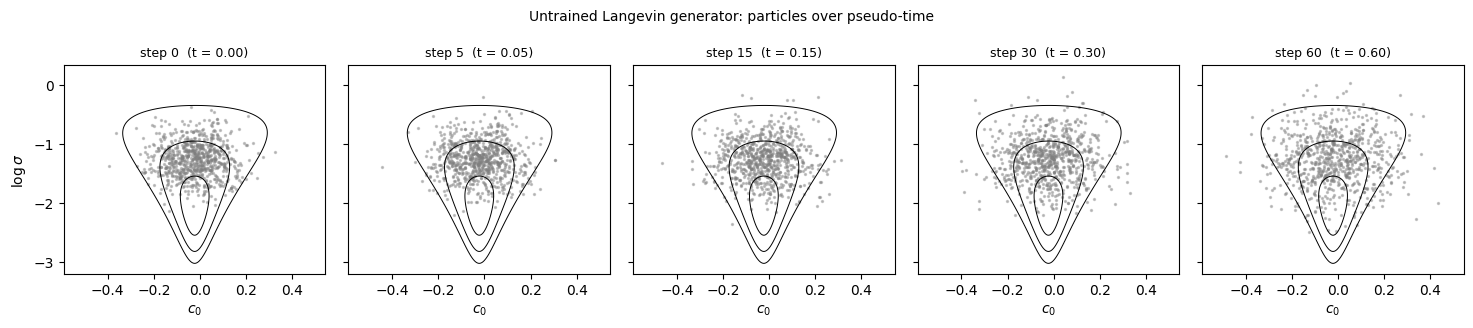

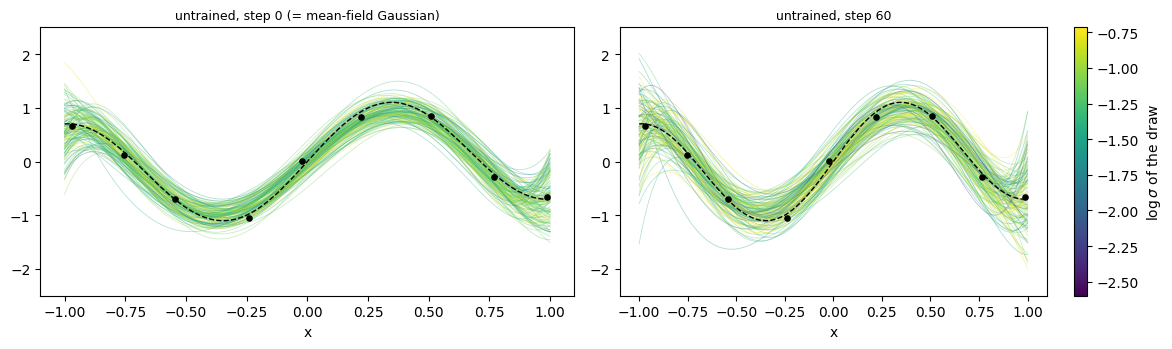

In [18]:
SNAP_STEPS = [0, 5, 15, 30, 60]


def trajectory_theta(group, n=2000, seed=0):
    torch.manual_seed(seed)
    with torch.no_grad():
        return z_to_theta(group.sample_trajectory(n, record_every=1))  # (K+1, n, DIM)


def plot_snapshots(traj, color, title):
    fig, axes = plt.subplots(1, len(SNAP_STEPS), figsize=(15, 3.3), sharex=True, sharey=True)
    for ax, k in zip(axes, SNAP_STEPS):
        exact_contours(ax)
        ax.scatter(traj[k, :800, J_SHOW], log_sigma_of(traj[k, :800]), s=2, alpha=0.4, color=color)
        ax.set_title(f"step {k}  (t = {k * STEP_SIZE:.2f})", fontsize=9)
        ax.set_xlabel(f"$c_{J_SHOW}$")
    axes[0].set_ylabel(r"$\log\sigma$")
    axes[0].set_xlim(C_AX[0], C_AX[-1])
    axes[0].set_ylim(LS_PLOT[0], LS_PLOT[-1])
    fig.suptitle(title, fontsize=10)
    plt.tight_layout()


traj_untrained = trajectory_theta(make_langevin(0))
plot_snapshots(traj_untrained, "tab:gray", "Untrained Langevin generator: particles over pseudo-time")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
plot_function_draws(axes[0], traj_untrained[0], by_sigma=True)
axes[0].set_title("untrained, step 0 (= mean-field Gaussian)", fontsize=9)
plot_function_draws(axes[1], traj_untrained[-1], by_sigma=True)
axes[1].set_title(f"untrained, step {NUM_STEPS}", fontsize=9)
sigma_colorbar(fig, axes[1])
plt.tight_layout()

### 7b. Training

Same `train_group` loop as the Gaussians, with `to_theta = z_to_theta`. The
fitted state and one canonical 4000-particle draw per seed are cached.

In [19]:
langevin = {}
for seed in LANGEVIN_SEEDS:
    def _compute(seed=seed):
        group = make_langevin(seed)
        t0 = time.time()
        hist = train_group(group, z_to_theta, seed=seed, **LANGEVIN_CFG)
        elapsed = time.time() - t0
        torch.manual_seed(1000 + seed)
        with torch.no_grad():
            z = group.sample_parameters(EVAL_N)
        return {"state_dict": group.state_dict(), "history": hist, "time": elapsed, "z": z}

    # cache key carries the gauss_iid version: the rescaling comes from that group
    payload = cache.get(f"langevin_seed{seed}_giid_v1_v1", _compute)
    group = make_langevin(seed)
    group.load_state_dict(payload["state_dict"])
    langevin[seed] = {**payload, "group": group, "theta": z_to_theta(payload["z"])}
    print(f"Langevin seed {seed}: trained in {payload['time']:6.1f}s, "
          f"final loss + log Z {payload['history'][-200:].sum(1).mean() + logZ:.3f}")

[cache miss] langevin_seed0_giid_v1_v1  ->  langevin_seed0_giid_v1_v1.pt  (computed in 179.6s)
Langevin seed 0: trained in  179.5s, final loss + log Z -0.433


[cache miss] langevin_seed1_giid_v1_v1  ->  langevin_seed1_giid_v1_v1.pt  (computed in 178.7s)
Langevin seed 1: trained in  178.6s, final loss + log Z -0.440


[cache miss] langevin_seed2_giid_v1_v1  ->  langevin_seed2_giid_v1_v1.pt  (computed in 178.2s)
Langevin seed 2: trained in  178.1s, final loss + log Z -0.436


[cache miss] langevin_seed3_giid_v1_v1  ->  langevin_seed3_giid_v1_v1.pt  (computed in 178.6s)
Langevin seed 3: trained in  178.5s, final loss + log Z -0.432


[cache miss] langevin_seed4_giid_v1_v1  ->  langevin_seed4_giid_v1_v1.pt  (computed in 179.6s)
Langevin seed 4: trained in  179.4s, final loss + log Z -0.419


### 7c. KL of the trained generators

$\mathrm{KL}(q\,\|\,p) = \mathbb{E}_q[-\log p(\theta\mid y)] - H[q]$. The
first term is exact (we know $\log p$). The entropy is estimated with the
kNN estimator on 4000 particles, in the rescaled coordinates. To measure
its bias, the same estimator is applied to 4000 *exact* posterior samples,
whose entropy we know; that bias is added back to every kNN-based KL. The
training-time curves use only 128 particles, where the estimator is more
biased, so they can dip below zero.

kNN entropy bias at N=4000 on exact samples: -0.033 nats


Langevin KL(q||p) per seed (bias-corrected): [0.156 0.161 0.156 0.132 0.158]
mean 0.153 +/- 0.012   (full-covariance ceiling 0.599)
seed with the median KL, shown in the plots below: 0


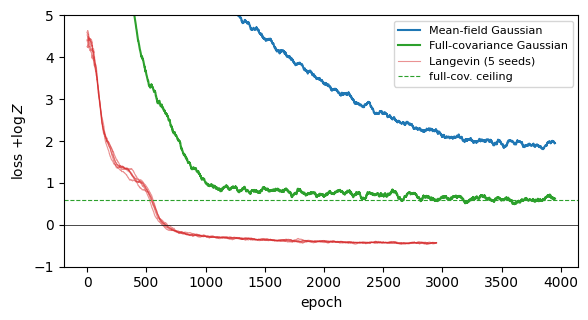

In [20]:
def knn_entropy_theta(theta, k=4):
    with torch.no_grad():
        return _knn_entropy((theta - PRE_M) / PRE_S, k=k).item() + LOG_DET_S


def kl_knn(theta):
    ce = -(log_joint(theta) - logZ).mean().item()
    return ce - knn_entropy_theta(theta)


KNN_BIAS = knn_entropy_theta(theta_exact[:EVAL_N]) - H_exact
print(f"kNN entropy bias at N={EVAL_N} on exact samples: {KNN_BIAS:+.3f} nats")
for seed in LANGEVIN_SEEDS:
    raw = kl_knn(langevin[seed]["theta"])
    langevin[seed]["kl_knn"], langevin[seed]["kl"] = raw, raw + KNN_BIAS
lang_kls = np.array([langevin[s]["kl"] for s in LANGEVIN_SEEDS])
print("Langevin KL(q||p) per seed (bias-corrected):", lang_kls.round(3))
print(f"mean {lang_kls.mean():.3f} +/- {lang_kls.std(ddof=1):.3f}   "
      f"(full-covariance ceiling {ceiling['full']['kl']:.3f})")
LANG_SHOW = LANGEVIN_SEEDS[int(np.argsort(lang_kls)[len(lang_kls) // 2])]
print(f"seed with the median KL, shown in the plots below: {LANG_SHOW}")

fig, ax = plt.subplots(figsize=(6, 3.3))
for kind in ["iid", "full"]:
    ax.plot(smooth(gauss[kind]["history"]) + logZ, color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
for i, seed in enumerate(LANGEVIN_SEEDS):
    ax.plot(smooth(langevin[seed]["history"]) + logZ, color=FAMILY_COLORS["langevin"], alpha=0.5, lw=0.8,
            label="Langevin (5 seeds)" if i == 0 else None)
ax.axhline(ceiling["full"]["kl"], color=FAMILY_COLORS["full"], ls="--", lw=0.8, label="full-cov. ceiling")
ax.axhline(0, color="k", lw=0.5)
ax.set_ylim(-1, 5)
ax.set_xlabel("epoch")
ax.set_ylabel(r"loss $+\log Z$")
ax.legend(fontsize=8)
plt.tight_layout()

### 7d. Inside the trained generator: particles over pseudo-time

The same snapshots as for the untrained generator, now with the trained
score network (median-KL seed). The particles start as the mean-field
Gaussian and are transported onto the funnel. Below: the paths of 25
individual particles, and the quantiles of $\log\sigma$ across the cloud as
a function of the step, against the exact posterior quantiles.

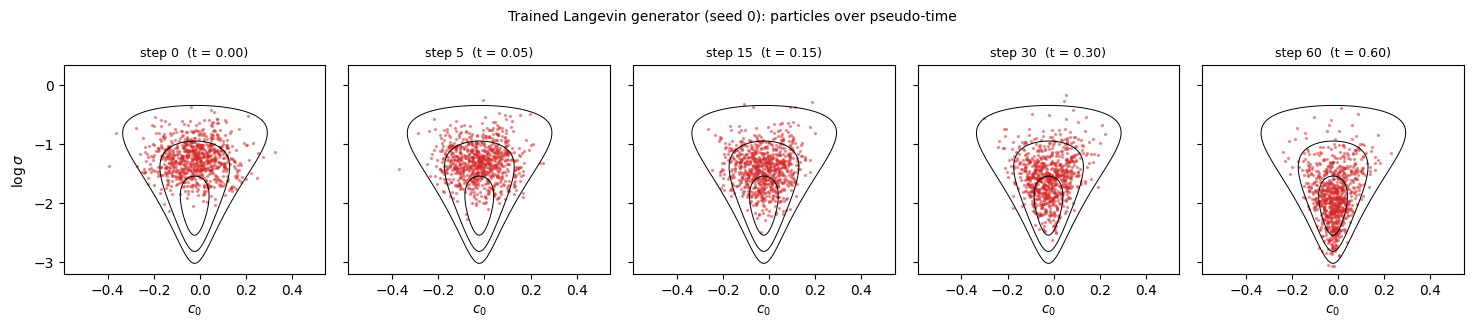

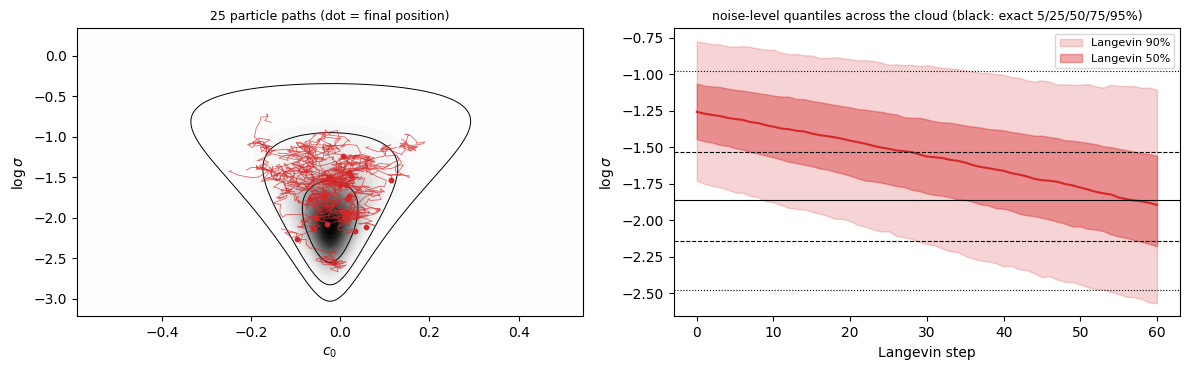

In [21]:
lang_group = langevin[LANG_SHOW]["group"]
traj = trajectory_theta(lang_group)
plot_snapshots(traj, FAMILY_COLORS["langevin"], f"Trained Langevin generator (seed {LANG_SHOW}): particles over pseudo-time")

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
exact_contours(axes[0], filled=True)
for k in range(25):
    axes[0].plot(traj[:, k, J_SHOW], log_sigma_of(traj[:, k]), color=FAMILY_COLORS["langevin"], lw=0.6, alpha=0.7)
    axes[0].scatter(traj[-1, k, J_SHOW], log_sigma_of(traj[-1:, k]), color=FAMILY_COLORS["langevin"], s=10, zorder=3)
axes[0].set_xlabel(f"$c_{J_SHOW}$")
axes[0].set_ylabel(r"$\log\sigma$")
axes[0].set_title("25 particle paths (dot = final position)", fontsize=9)

steps = np.arange(NUM_STEPS + 1)
qs = torch.tensor([0.05, 0.25, 0.5, 0.75, 0.95])
traj_q = torch.quantile(log_sigma_of(traj.reshape(-1, DIM)).reshape(NUM_STEPS + 1, -1), qs, dim=1)
exact_q = torch.quantile(log_sigma_of(theta_exact), qs)
axes[1].fill_between(steps, traj_q[0], traj_q[4], color=FAMILY_COLORS["langevin"], alpha=0.2, label="Langevin 90%")
axes[1].fill_between(steps, traj_q[1], traj_q[3], color=FAMILY_COLORS["langevin"], alpha=0.4, label="Langevin 50%")
axes[1].plot(steps, traj_q[2], color=FAMILY_COLORS["langevin"])
for v, ls in zip(exact_q, [":", "--", "-", "--", ":"]):
    axes[1].axhline(v, color="k", ls=ls, lw=0.8)
axes[1].set_xlabel("Langevin step")
axes[1].set_ylabel(r"$\log\sigma$")
axes[1].set_title("noise-level quantiles across the cloud (black: exact 5/25/50/75/95%)", fontsize=9)
axes[1].legend(fontsize=8)
plt.tight_layout()

The same transport, pushed forward to function space: function draws at
step 0, halfway, and at the end, coloured by each particle's noise level.

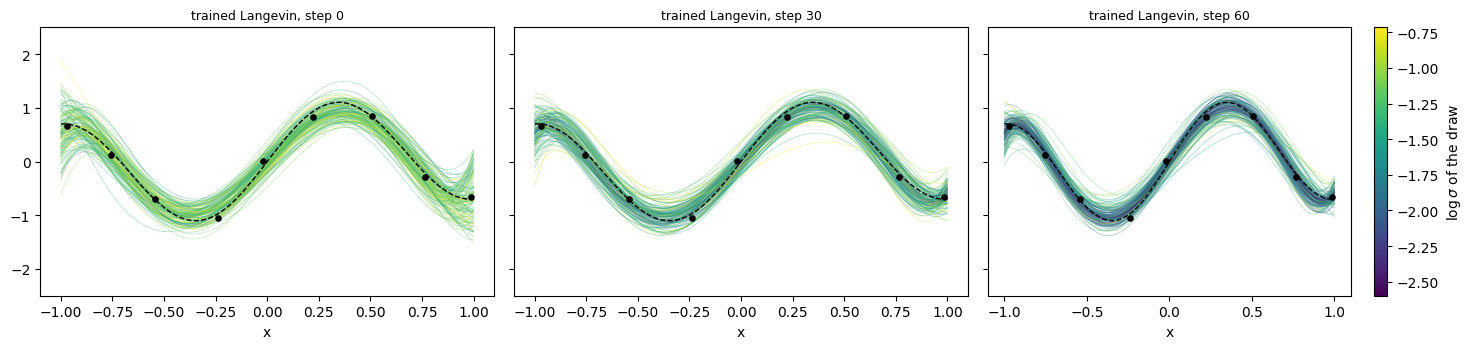

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(15, 3.6), sharey=True)
for ax, k in zip(axes, [0, NUM_STEPS // 2, NUM_STEPS]):
    plot_function_draws(ax, traj[k], by_sigma=True)
    ax.set_title(f"trained Langevin, step {k}", fontsize=9)
sigma_colorbar(fig, axes[-1])
plt.tight_layout()

### 7e. The learned drift vs. the exact score

The score network is a vector field on the 7-D parameter space. Below, both
fields on the $(c_{j}, \log\sigma)$ slice (the other coefficients set to
their exact conditional mean $m(u)$), drawn as streamlines in $\theta$
coordinates and coloured by log speed, over the exact density.

The learned drift **need not equal** the exact score
$\nabla_z \log p$: it is a time-independent field that only has to move a
cloud from the mean-field Gaussian to the posterior in $T = 0.6$, and it is
only constrained where the particles actually travel. Agreement in the
high-density region and disagreement far from it are both expected.

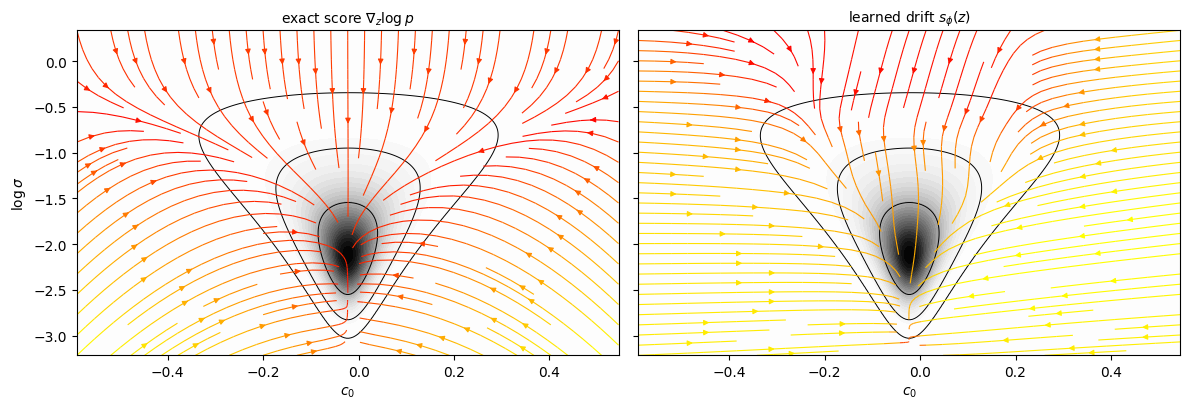

In [23]:
def slice_points(nc=30, nu=30):
    cs = torch.linspace(C_AX[0].item(), C_AX[-1].item(), nc)
    us = torch.linspace(U_PLOT[0].item(), U_PLOT[-1].item(), nu)
    m, _ = conditional_c(us)
    th = torch.cat([m, us[:, None]], 1)[:, None, :].repeat(1, nc, 1)  # (nu, nc, DIM)
    th[:, :, J_SHOW] = cs[None, :]
    return cs, MU_LOGSIG + us, th.reshape(-1, DIM)


def exact_score_z(z):
    z = z.detach().requires_grad_(True)
    return torch.autograd.grad(log_joint(z_to_theta(z)).sum(), z)[0]


cs, lss, th_slice = slice_points()
z_slice = (th_slice - PRE_M) / PRE_S
with torch.no_grad():
    learned = lang_group._score(z_slice)  # the drift network itself (private helper)
exact_sc = exact_score_z(z_slice)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for ax, field, title in [(axes[0], exact_sc, r"exact score $\nabla_z \log p$"),
                         (axes[1], learned, "learned drift $s_\\phi(z)$")]:
    # drift in theta coordinates: d theta = s * d z
    U = (PRE_S[J_SHOW] * field[:, J_SHOW]).reshape(len(lss), len(cs))
    V = (PRE_S[-1] * field[:, -1]).reshape(len(lss), len(cs))
    speed = torch.log10(torch.hypot(U, V) + 1e-12)
    exact_contours(ax, filled=True)
    ax.streamplot(cs.numpy(), lss.numpy(), U.numpy(), V.numpy(), color=speed.numpy(), cmap="autumn",
                  density=1.1, linewidth=0.8, arrowsize=0.8)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel(f"$c_{J_SHOW}$")
axes[0].set_ylabel(r"$\log\sigma$")
plt.tight_layout()

### 7f. Reference: unadjusted Langevin with the *exact* score

What would the same dynamics do with the exact score instead of a learned
one? Same rescaled coordinates, same step size $h = 10^{-2}$, same initial
cloud; we record the particles after 60 steps (the trained generator's
budget) and after 2000 steps (close to stationarity, up to the
discretization bias of $h$). This separates two questions: how good is the
ULA *discretization* at this step size, and how much does the trained
network achieve within 60 steps.

[cache miss] exact_score_ula_giid_v1_v1  ->  exact_score_ula_giid_v1_v1.pt  (computed in 4.7s)
exact-score ULA,   60 steps: KL(q||p) = 0.723 (kNN, bias-corrected)
exact-score ULA, 2000 steps: KL(q||p) = -0.010 (kNN, bias-corrected)
trained Langevin, 60 steps (seed 0): KL(q||p) = 0.156


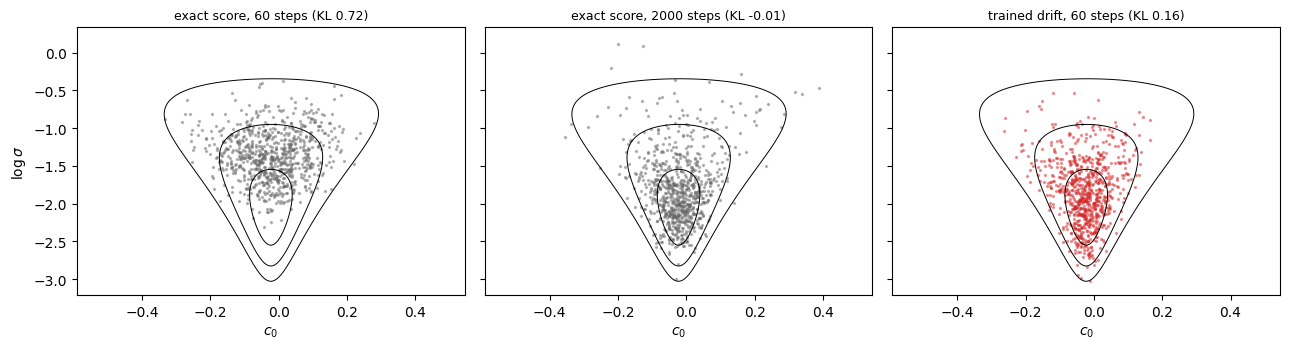

In [24]:
def exact_score_ula(record=(60, 2000), n=EVAL_N, seed=0):
    torch.manual_seed(seed)
    z = torch.randn(n, DIM)
    out = {}
    for k in range(1, max(record) + 1):
        z = (z + STEP_SIZE * exact_score_z(z) + math.sqrt(2 * STEP_SIZE) * torch.randn_like(z)).detach()
        if k in record:
            out[k] = z_to_theta(z)
    return out


ula = cache.get("exact_score_ula_giid_v1_v1", exact_score_ula)
kl_ula = {k: kl_knn(th) + KNN_BIAS for k, th in ula.items()}
for k, v in kl_ula.items():
    print(f"exact-score ULA, {k:4d} steps: KL(q||p) = {v:.3f} (kNN, bias-corrected)")
print(f"trained Langevin, {NUM_STEPS} steps (seed {LANG_SHOW}): KL(q||p) = {langevin[LANG_SHOW]['kl']:.3f}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharex=True, sharey=True)
panels = [(ula[60], "0.4", f"exact score, 60 steps (KL {kl_ula[60]:.2f})"),
          (ula[2000], "0.4", f"exact score, 2000 steps (KL {kl_ula[2000]:.2f})"),
          (langevin[LANG_SHOW]["theta"], FAMILY_COLORS["langevin"],
           f"trained drift, 60 steps (KL {langevin[LANG_SHOW]['kl']:.2f})")]
for ax, (th, color, title) in zip(axes, panels):
    exact_contours(ax)
    ax.scatter(th[:800, J_SHOW], log_sigma_of(th[:800]), s=2, alpha=0.4, color=color)
    ax.set_title(title, fontsize=9)
    ax.set_xlabel(f"$c_{J_SHOW}$")
axes[0].set_ylabel(r"$\log\sigma$")
axes[0].set_xlim(C_AX[0], C_AX[-1])
axes[0].set_ylim(LS_PLOT[0], LS_PLOT[-1])
plt.tight_layout()

## 8. Side-by-side comparison

From here on every family is represented by 4000 samples: draws from the
fitted Gaussians, and the cached canonical draw for Langevin (median-KL
seed unless stated otherwise).

### 8a. KL divergence to the exact posterior

* Gaussian families: exact KL, using the analytic $\log q$.
* Langevin: kNN entropy estimate, bias-corrected as in 7c.
* **Check of the correction:** the same kNN-based estimate applied to 4000
  samples from each *Gaussian*, whose exact KL we know. If the corrected
  kNN numbers match the exact ones, the Langevin numbers are on the same
  footing.

family                      exact KL  kNN corr.  ceiling
Mean-field Gaussian            1.922      1.994    1.040
Full-covariance Gaussian       0.602      0.593    0.599
Langevin                         nan      0.153      nan
Langevin: mean over 5 seeds 0.153 +/- 0.012, range [0.132, 0.161]


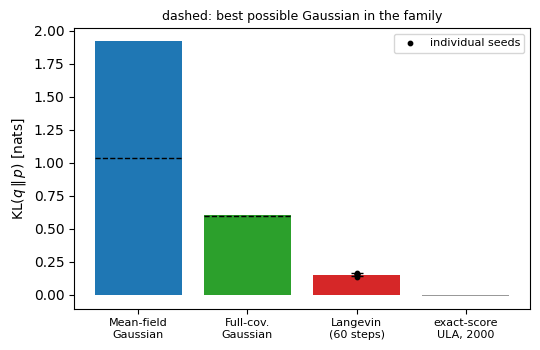

In [25]:
def family_samples(kind, n=EVAL_N):
    if kind == "exact":
        return theta_exact[:n]
    if kind == "langevin":
        return langevin[LANG_SHOW]["theta"][:n]
    return gauss_samples(kind, n)


kl_table = {}
for kind in ["iid", "full"]:
    raw = kl_knn(gauss_samples(kind))
    kl_table[kind] = {"exact": gauss[kind]["kl"], "knn_corr": raw + KNN_BIAS, "ceiling": ceiling[kind]["kl"]}
kl_table["langevin"] = {"exact": np.nan, "knn_corr": lang_kls.mean(), "ceiling": np.nan}

print(f"{'family':26s} {'exact KL':>9s} {'kNN corr.':>10s} {'ceiling':>8s}")
for kind in FAMILIES:
    r = kl_table[kind]
    print(f"{FAMILY_LABELS[kind]:26s} {r['exact']:9.3f} {r['knn_corr']:10.3f} {r['ceiling']:8.3f}")
print(f"Langevin: mean over {len(LANGEVIN_SEEDS)} seeds {lang_kls.mean():.3f} +/- {lang_kls.std(ddof=1):.3f}, "
      f"range [{lang_kls.min():.3f}, {lang_kls.max():.3f}]")

fig, ax = plt.subplots(figsize=(5.5, 3.6))
ax.bar(0, kl_table["iid"]["exact"], color=FAMILY_COLORS["iid"])
ax.bar(1, kl_table["full"]["exact"], color=FAMILY_COLORS["full"])
ax.bar(2, lang_kls.mean(), yerr=lang_kls.std(ddof=1), color=FAMILY_COLORS["langevin"], capsize=4)
ax.scatter(np.full(len(lang_kls), 2.0), lang_kls, color="k", s=10, zorder=3, label="individual seeds")
ax.bar(3, kl_ula[2000], color="0.6")
for i, kind in enumerate(["iid", "full"]):
    ax.hlines(ceiling[kind]["kl"], i - 0.4, i + 0.4, colors="k", linestyles="--", lw=1)
ax.set_xticks([0, 1, 2, 3], ["Mean-field\nGaussian", "Full-cov.\nGaussian", "Langevin\n(60 steps)",
                             "exact-score\nULA, 2000"], fontsize=8)
ax.set_ylabel(r"KL$(q\,\|\,p)$ [nats]")
ax.set_title("dashed: best possible Gaussian in the family", fontsize=9)
ax.legend(fontsize=8)
plt.tight_layout()

### 8b. Shape: samples over the exact funnel slice

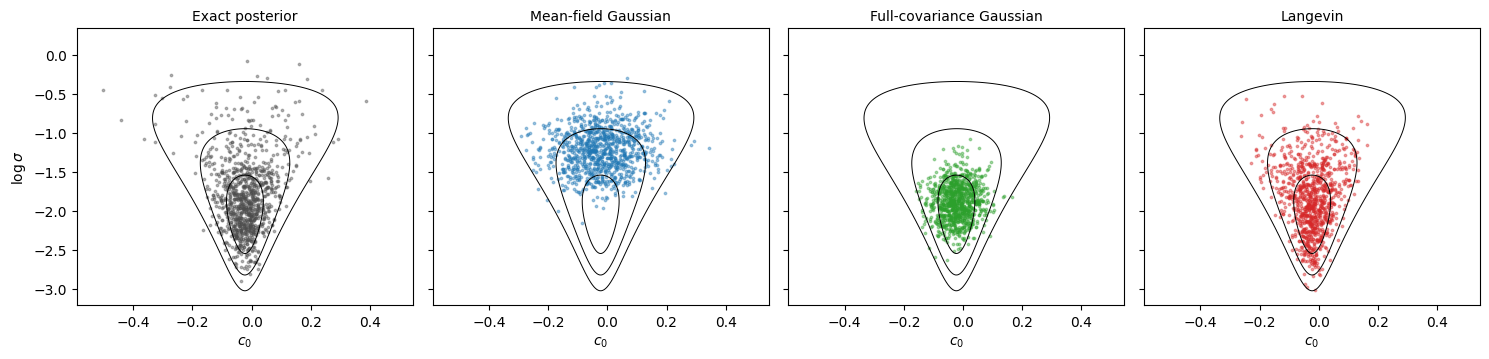

In [26]:
fig, axes = plt.subplots(1, 4, figsize=(15, 3.7), sharex=True, sharey=True)
for ax, kind in zip(axes, ["exact"] + FAMILIES):
    th = family_samples(kind)[:1000]
    exact_contours(ax)
    ax.scatter(th[:, J_SHOW], log_sigma_of(th), s=3, alpha=0.4, color=FAMILY_COLORS[kind])
    ax.set_title(FAMILY_LABELS[kind], fontsize=10)
    ax.set_xlabel(f"$c_{J_SHOW}$")
axes[0].set_ylabel(r"$\log\sigma$")
axes[0].set_xlim(C_AX[0], C_AX[-1])
axes[0].set_ylim(LS_PLOT[0], LS_PLOT[-1])
plt.tight_layout()

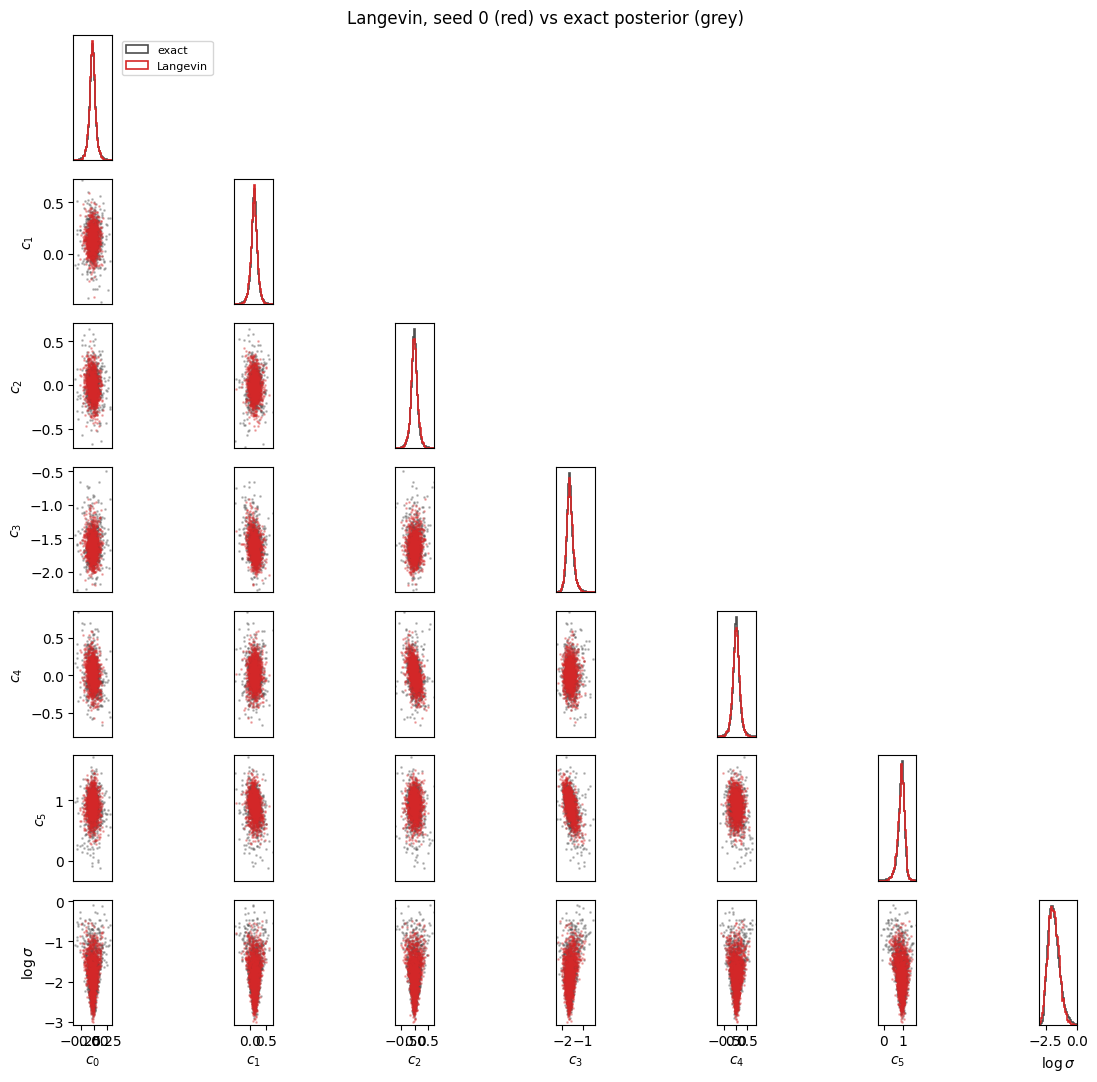

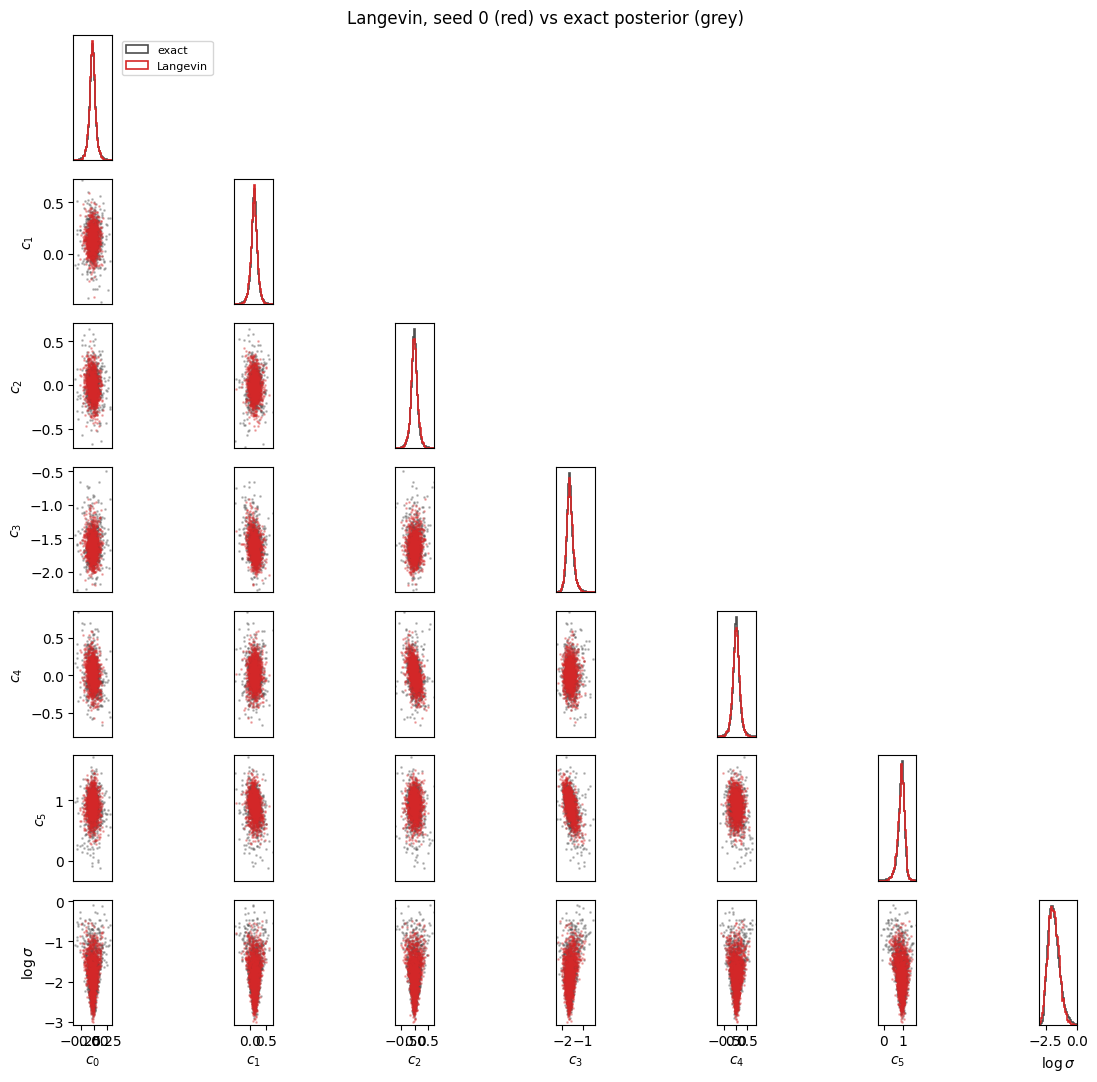

In [27]:
corner([("exact", theta_exact, FAMILY_COLORS["exact"]),
        ("Langevin", family_samples("langevin"), FAMILY_COLORS["langevin"])],
       title=f"Langevin, seed {LANG_SHOW} (red) vs exact posterior (grey)")

### 8c. Conditional spread and mean vs. $\sigma$ (no entropy estimate involved)

Bin the samples by $u$ (deciles of the exact $u$ marginal) and compute
$\mathrm{sd}(c_j\mid u)$ and $\mathbb{E}[c_j\mid u]$ per bin, against the
exact curves $\sqrt{C_{jj}(u)}$ and $m_j(u)$. Any Gaussian gives a flat
spread and a straight mean. The table gives the *funnel ratio* (spread in
the top decile over the bottom decile) for every coefficient; the exact
value is the target, and a Gaussian scores 1.

funnel ratio sd(c_j | top u-decile) / sd(c_j | bottom u-decile)
                               c0     c1     c2     c3     c4     c5
Exact posterior              5.14   5.13   4.93   5.12   4.85   4.82
Mean-field Gaussian           nan    nan    nan    nan    nan    nan
Full-covariance Gaussian     1.10   1.03   0.97   1.12   0.94   1.07
Langevin                     3.94   3.51   3.61   3.22   3.48   3.16
Langevin, 5-seed mean        4.00   3.60   3.56   3.37   3.32   3.25


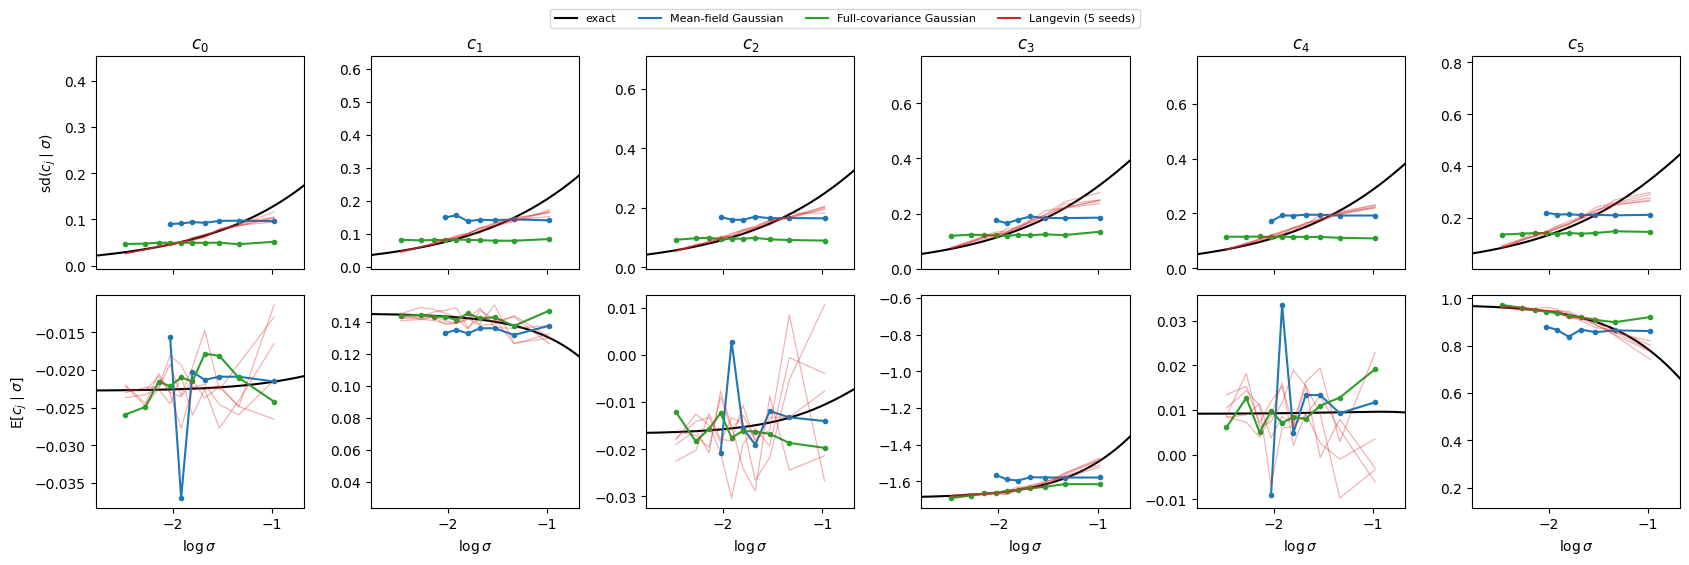

In [28]:
EDGES = torch.quantile(theta_exact[:, -1], torch.linspace(0, 1, 11))
EDGES[0], EDGES[-1] = -torch.inf, torch.inf
_bins = [(theta_exact[:, -1] >= EDGES[b]) & (theta_exact[:, -1] < EDGES[b + 1]) for b in range(10)]
LS_CENTERS = MU_LOGSIG + torch.stack([theta_exact[sel, -1].median() for sel in _bins])


def binned_stats(th, min_count=30):
    sd = torch.full((10, P), float("nan"))
    mean = torch.full((10, P), float("nan"))
    for b in range(10):
        sel = (th[:, -1] >= EDGES[b]) & (th[:, -1] < EDGES[b + 1])
        if sel.sum() >= min_count:
            sd[b], mean[b] = th[sel, :P].std(0), th[sel, :P].mean(0)
    return sd, mean


def ratio(sd):
    return (sd[-1] / sd[0]).numpy()


cond = {"exact": binned_stats(theta_exact)}
cond.update({kind: binned_stats(gauss_samples(kind, 20_000)) for kind in ["iid", "full"]})
cond["langevin"] = binned_stats(family_samples("langevin"))
cond_lang_all = [binned_stats(langevin[s]["theta"]) for s in LANGEVIN_SEEDS]
lang_ratios = np.array([ratio(sd) for sd, _ in cond_lang_all])

print("funnel ratio sd(c_j | top u-decile) / sd(c_j | bottom u-decile)")
print(f"{'':26s}" + "".join(f"{'c' + str(j):>7s}" for j in range(P)))
for kind in ["exact"] + FAMILIES:
    print(f"{FAMILY_LABELS[kind]:26s}" + "".join(f"{v:7.2f}" for v in ratio(cond[kind][0])))
print(f"{'Langevin, 5-seed mean':26s}" + "".join(f"{v:7.2f}" for v in np.nanmean(lang_ratios, 0)))

fig, axes = plt.subplots(2, P, figsize=(17, 5.5), sharex=True)
for j in range(P):
    axes[0, j].plot(LS_PLOT, C_plot[:, j, j].sqrt(), "k", lw=1.5)
    axes[1, j].plot(LS_PLOT, m_plot[:, j], "k", lw=1.5)
    for kind in ["iid", "full"]:
        axes[0, j].plot(LS_CENTERS, cond[kind][0][:, j], "o-", ms=3, color=FAMILY_COLORS[kind])
        axes[1, j].plot(LS_CENTERS, cond[kind][1][:, j], "o-", ms=3, color=FAMILY_COLORS[kind])
    for sd, mean in cond_lang_all:
        axes[0, j].plot(LS_CENTERS, sd[:, j], color=FAMILY_COLORS["langevin"], alpha=0.35, lw=0.9)
        axes[1, j].plot(LS_CENTERS, mean[:, j], color=FAMILY_COLORS["langevin"], alpha=0.35, lw=0.9)
    axes[0, j].set_title(f"$c_{j}$")
    axes[1, j].set_xlabel(r"$\log\sigma$")
    axes[0, j].set_xlim(LS_CENTERS[0].item() - 0.3, LS_CENTERS[-1].item() + 0.3)
axes[0, 0].set_ylabel(r"sd$(c_j \mid \sigma)$")
axes[1, 0].set_ylabel(r"E$[c_j \mid \sigma]$")
handles = [plt.Line2D([], [], color="k", label="exact")] + [
    plt.Line2D([], [], color=FAMILY_COLORS[k], label=FAMILY_LABELS[k] + (" (5 seeds)" if k == "langevin" else ""))
    for k in FAMILIES]
fig.legend(handles=handles, loc="upper center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, 1.03))
plt.tight_layout()

### 8d. The noise-level marginal

                               q05  median     q95
Exact posterior              0.084   0.156   0.376
Mean-field Gaussian          0.185   0.289   0.458
Full-covariance Gaussian     0.102   0.150   0.223
Langevin                     0.077   0.156   0.335


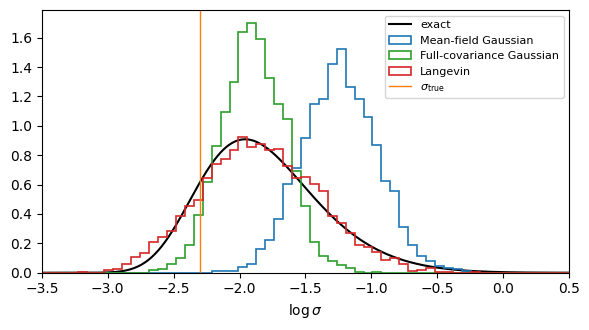

In [29]:
qs = torch.tensor([0.05, 0.5, 0.95])
sigma_q = {}
print(f"{'':26s} {'q05':>7s} {'median':>7s} {'q95':>7s}")
for kind in ["exact"] + FAMILIES:
    th = theta_exact if kind == "exact" else family_samples(kind)
    sigma_q[kind] = torch.quantile(log_sigma_of(th).exp(), qs).numpy()
    print(f"{FAMILY_LABELS[kind]:26s} " + " ".join(f"{v:7.3f}" for v in sigma_q[kind]))

_, ax = plt.subplots(figsize=(6, 3.4))
ax.plot(ls_grid, log_post_u.exp(), "k", lw=1.5, label="exact")
bins = np.linspace(-3.5, 0.5, 60)
for kind in FAMILIES:
    ax.hist(log_sigma_of(family_samples(kind)).numpy(), bins=bins, density=True, histtype="step", lw=1.2,
            color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
ax.axvline(math.log(SIGMA_TRUE), color="tab:orange", lw=1, label=r"$\sigma_\mathrm{true}$")
ax.set_xlim(-3.5, 0.5)
ax.set_xlabel(r"$\log\sigma$")
ax.legend(fontsize=8)
plt.tight_layout()

### 8e. Pushforward to function space and to predictions

Top row: function draws for each family, coloured by $\sigma$ (compare with
the exact draws in section 5). Bottom row: each family's 90% and 99%
posterior-predictive bands (lines) over the exact ones (shaded).

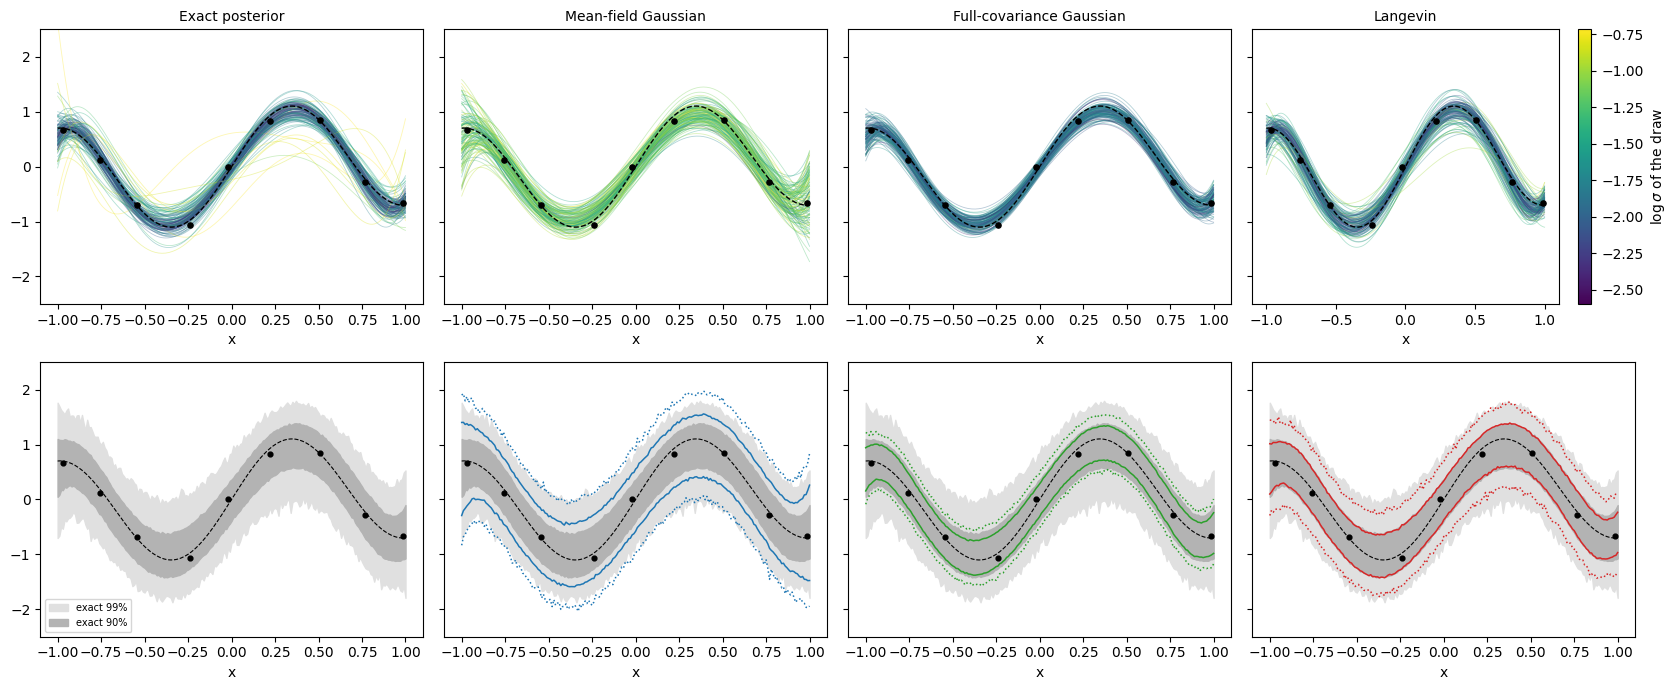

In [30]:
band_q = torch.tensor([0.005, 0.05, 0.5, 0.95, 0.995])
bands = {kind: torch.quantile(predictive_draws(family_samples(kind)), band_q, dim=0) for kind in ["exact"] + FAMILIES}

fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey=True)
for col, kind in enumerate(["exact"] + FAMILIES):
    plot_function_draws(axes[0, col], family_samples(kind), by_sigma=True)
    axes[0, col].set_title(FAMILY_LABELS[kind], fontsize=10)
    ax = axes[1, col]
    be = bands["exact"]
    ax.fill_between(XB, be[0], be[4], color="0.88", label="exact 99%")
    ax.fill_between(XB, be[1], be[3], color="0.7", label="exact 90%")
    if kind != "exact":
        b = bands[kind]
        for i, ls in [(0, ":"), (1, "-"), (3, "-"), (4, ":")]:
            ax.plot(XB, b[i], ls, color=FAMILY_COLORS[kind], lw=1.1)
    ax.plot(XB, truth(XB), "k--", lw=0.8)
    ax.scatter(x_train[:, 0], y_train, color="k", s=12, zorder=3)
    ax.set_xlabel("x")
sigma_colorbar(fig, axes[0, -1])
axes[1, 0].legend(fontsize=7, loc="lower left")
axes[0, 0].set_ylim(-2.5, 2.5)
plt.tight_layout()

**Predictive distribution at a single input.** The scale mixture over
$\sigma$ gives the exact predictive heavier-than-Gaussian tails. Histograms
of $y^\ast$ at two inputs, one between training points and one at the edge
of the domain, on a log density axis so the tails are visible.

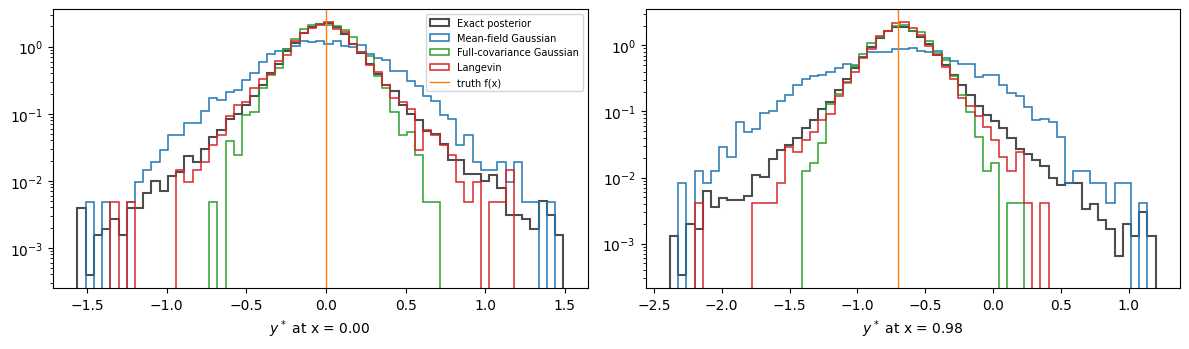

In [31]:
X_PROBE = torch.tensor([[0.0], [0.98]])
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, xp in zip(axes, X_PROBE):
    ys = {kind: predictive_draws(theta_exact[:50_000] if kind == "exact" else family_samples(kind), x=xp[None])[:, 0]
          for kind in ["exact"] + FAMILIES}
    lo, hi = torch.quantile(ys["exact"], torch.tensor([0.0005, 0.9995])).tolist()
    bins = np.linspace(lo, hi, 60)
    for kind, y in ys.items():
        ax.hist(y.numpy(), bins=bins, density=True, histtype="step", lw=1.5 if kind == "exact" else 1.1,
                color=FAMILY_COLORS[kind], label=FAMILY_LABELS[kind])
    ax.axvline(truth(xp)[0].item(), color="tab:orange", lw=1, label="truth f(x)")
    ax.set_yscale("log")
    ax.set_xlabel(f"$y^*$ at x = {xp.item():.2f}")
axes[0].legend(fontsize=7)
plt.tight_layout()

### 8f. Held-out predictive performance

Fresh data from the true process: 2000 points, $x \sim U[-1, 1]$, noise
$\sigma_\mathrm{true}$. For each family, the mean log predictive density
$\frac{1}{T}\sum_t \log \frac{1}{S}\sum_s N(y_t; f_s(x_t), \sigma_s^2)$,
the empirical coverage of the central 90% predictive interval, and the 99%
band width relative to the exact one (averaged over $x$). The exact
posterior is the Bayes-optimal reference *given these nine points*; it is
not expected to be perfectly calibrated against the truth.

In [32]:
_gt = torch.Generator().manual_seed(123)
x_test = 2 * torch.rand(2000, 1, generator=_gt) - 1
y_test = truth(x_test[:, 0]) + SIGMA_TRUE * torch.randn(2000, generator=_gt)

heldout = {}
w99_exact = bands["exact"][4] - bands["exact"][0]
print(f"{'':26s} {'LPD':>7s} {'cover90':>8s} {'w99/exact':>10s}")
for kind in ["exact"] + FAMILIES:
    th = family_samples(kind)
    f_t, s_t = functions_of(th, x_test), log_sigma_of(th).exp()[:, None]
    logdens = -0.5 * ((y_test[None] - f_t) / s_t) ** 2 - torch.log(s_t) - 0.5 * LOG2PI
    lpd = (torch.logsumexp(logdens, 0) - math.log(th.shape[0])).mean().item()
    lo, hi = torch.quantile(predictive_draws(th, x_test), torch.tensor([0.05, 0.95]), dim=0)
    cover = ((y_test >= lo) & (y_test <= hi)).double().mean().item()
    w99 = ((bands[kind][4] - bands[kind][0]) / w99_exact).mean().item()
    heldout[kind] = {"lpd": lpd, "cover90": cover, "w99_ratio": w99}
    print(f"{FAMILY_LABELS[kind]:26s} {lpd:7.3f} {cover:8.3f} {w99:10.3f}")

                               LPD  cover90  w99/exact


Exact posterior              0.496    1.000      1.000


Mean-field Gaussian          0.079    1.000      1.106


Full-covariance Gaussian     0.557    0.993      0.570


Langevin                     0.501    1.000      0.825


## 9. Export tables for the paper

Plain-text tables in `~/projects/salt/doc/paper/stochastic_surrogates/dat/`,
with the same `np.savetxt` convention as `toy_sine_*`.

In [33]:
PAPER_DAT_DIR.mkdir(parents=True, exist_ok=True)
pre = str(PAPER_DAT_DIR / "toy_funnel_")

with open(f"{pre}kl.txt", "w") as f:
    f.write("family kl kl_knn_corrected kl_ceiling\n")
    for kind in ["iid", "full"]:
        r = kl_table[kind]
        f.write(f"{kind} {r['exact']:.6f} {r['knn_corr']:.6f} {r['ceiling']:.6f}\n")
    f.write(f"langevin {lang_kls.mean():.6f} {lang_kls.mean():.6f} nan\n")
    f.write(f"ula_exact_score_2000 {kl_ula[2000]:.6f} {kl_ula[2000]:.6f} nan\n")
np.savetxt(f"{pre}kl_langevin_seeds.txt", np.column_stack([LANGEVIN_SEEDS, lang_kls]),
           header="seed kl_knn_corrected", comments="")

U_mesh, C_mesh = torch.meshgrid(LS_PLOT, C_AX, indexing="ij")
np.savetxt(f"{pre}exact_density.txt", np.column_stack([C_mesh.flatten(), U_mesh.flatten(), DENS.flatten()]),
           header=f"c{J_SHOW} logsigma density", comments="")
with open(f"{pre}exact_levels.txt", "w") as f:
    f.write("mass level\n" + "".join(f"{m} {lvl:.8e}\n" for m, lvl in zip([0.99, 0.9, 0.5], LEVELS)))
for kind in ["exact"] + FAMILIES:
    th = family_samples(kind)[:1000]
    np.savetxt(f"{pre}samples_{kind}.txt", np.column_stack([th[:, J_SHOW], log_sigma_of(th)]),
               header=f"c{J_SHOW} logsigma", comments="")
for k in SNAP_STEPS:
    np.savetxt(f"{pre}traj_step{k}.txt", np.column_stack([traj[k, :1000, J_SHOW], log_sigma_of(traj[k, :1000])]),
               header=f"c{J_SHOW} logsigma", comments="")

np.savetxt(f"{pre}cond_exact.txt", np.column_stack([LS_PLOT, C_plot[:, J_SHOW, J_SHOW].sqrt(), m_plot[:, J_SHOW]]),
           header="logsigma sd mean", comments="")
cols, hdr = [LS_CENTERS], ["logsigma"]
for kind in FAMILIES:
    cols += [cond[kind][0][:, J_SHOW], cond[kind][1][:, J_SHOW]]
    hdr += [f"{kind}_sd", f"{kind}_mean"]
np.savetxt(f"{pre}cond_binned.txt", np.column_stack(cols), header=" ".join(hdr), comments="")
np.savetxt(f"{pre}funnel_ratio.txt",
           np.column_stack([np.arange(P)] + [ratio(cond[k][0]) for k in ["exact"] + FAMILIES]),
           header="coeff exact iid full langevin", comments="")
np.savetxt(f"{pre}sigma_marginal_exact.txt", np.column_stack([ls_grid[::10], log_post_u.exp()[::10]]),
           header="logsigma density", comments="")

cols, hdr = [XB], ["x"]
for kind in ["exact"] + FAMILIES:
    cols += list(bands[kind])
    hdr += [f"{kind}_{n}" for n in ["q005", "q05", "q50", "q95", "q995"]]
np.savetxt(f"{pre}predictive_band.txt", np.column_stack(cols), header=" ".join(hdr), comments="")
with open(f"{pre}heldout.txt", "w") as f:
    f.write("family lpd cover90 w99_ratio\n")
    for kind in ["exact"] + FAMILIES:
        r = heldout[kind]
        f.write(f"{kind} {r['lpd']:.6f} {r['cover90']:.6f} {r['w99_ratio']:.6f}\n")
np.savetxt(f"{pre}data.txt", np.column_stack([x_train[:, 0], y_train]), header="x y", comments="")
print("wrote toy_funnel_*.txt to", PAPER_DAT_DIR)

wrote toy_funnel_*.txt to /home/pmrobbe/projects/salt/doc/paper/stochastic_surrogates/dat


## 10. Conclusions

*To be written from the executed numbers; nothing is claimed in advance.*

In [34]:
print(f"total notebook wall time: {time.time() - _notebook_start:.1f}s")

total notebook wall time: 953.5s
